# Pan-Cancer Tumour-Type Classifier from Tissue Genomics

**Dataset:** China Pan-Cancer (OrigiMed 2020) via cBioPortal  
**Task:** Predict tumour site from somatic mutation and copy-number alteration (CNA) profiles  
**Modalities:** binary mutation matrix + discrete CNA matrix  

---
Each code section is
preceded by a short explanation of what I am doing and why.


## Setup

Standard imports plus a `DATA_DIR` variable: point this at the folder that
contains the five cBioPortal files before running anything else.


In [8]:
# Importing necessary libraries
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (balanced_accuracy_score,
                             confusion_matrix,
                             classification_report)
warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Data directory and change to the directory containing the dataset
import os

DATA_DIR = os.path.expanduser("~/Desktop/Assesment/pan_origimed_2020")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


## Part 2: Complete Cases, Feature Selection & Transformation

### 2.1 Load raw files

We load the three files that carry our features and labels:
`data_clinical_sample.txt` for cancer-type labels, `data_mutations.txt` for
somatic variants, and `data_cna.txt` for discrete copy-number calls
(-2, -1, 0, 1, 2).  The `data_cna_log2.txt` file contains the continuous
log₂-ratio version which we will use for the standardised CNA features.
The first four header rows in the clinical files are cBioPortal metadata;
we skip them with `skiprows=4`.


In [9]:
# Clinical Sample file 
sample_df = pd.read_csv(
    os.path.join(DATA_DIR, "data_clinical_sample.txt"),
    sep="\t", skiprows=4
)
print(f"Loaded sample file: {sample_df.shape[0]:,} samples, "
      f"{sample_df['CANCER_TYPE'].nunique()} cancer types")

# Mutation file (long format: one row per variant)
mut_raw = pd.read_csv(
    os.path.join(DATA_DIR, "data_mutations.txt"),
    sep="\t", comment="#", low_memory=False,
    usecols=["Hugo_Symbol", "Tumor_Sample_Barcode"]
)
print(f"Loaded mutations file: {len(mut_raw):,} variant rows, "
      f"{mut_raw['Tumor_Sample_Barcode'].nunique():,} unique samples")

# Discrete CNA (same shape, binary values) 
cna_raw = pd.read_csv(
    os.path.join(DATA_DIR, "data_cna.txt"),
    sep="\t", index_col=0
).drop(columns=["Entrez_Gene_Id"], errors="ignore")

# log2-transformed CNA (same shape, continuous values)

cna_log2_raw = pd.read_csv(
    os.path.join(DATA_DIR, "data_cna_log2.txt"),
    sep="\t", index_col=0
).drop(columns=["Entrez_Gene_Id"], errors="ignore")

print(f"CNA matrix (genes × samples): {cna_raw.shape}")

sample_df.head()



Loaded sample file: 10,194 samples, 25 cancer types
Loaded mutations file: 99,895 variant rows, 9,815 unique samples
CNA matrix (genes × samples): (397, 10194)


,PATIENT_ID,SAMPLE_ID,CANCER_TYPE,CANCER_TYPE_DETAILED,AJCC_PATHOLOGIC_TUMOR_STAGE,SPECIMEN_TYPE,SAMPLE_TYPE,SPECIMEN_PRESERVATION_TYPE,TUMOR_PURTITY,GDNA(NG),COVERAGE_MEAN,TMB_NONSYNONYMOUS
0,Patient0001,P-0001,Colorectal Carcinoma,Colorectal Adenocarcinoma,IV,Surgery,Primary,FFPE,45,4776,1171.0,0.333333
1,Patient0002,P-0002,Colorectal Carcinoma,Colorectal Adenocarcinoma,II,Surgery,Primary,FFPE,40,3876,476.0,0.300000
2,Patient0003,P-0003,Colorectal Carcinoma,Colorectal Adenocarcinoma,III,Surgery,Primary,FFPE,45,9720,1277.0,0.500000
3,Patient0004,P-0004,Colorectal Carcinoma,Colorectal Adenocarcinoma,III,Surgery,Primary,FFPE,60,33840,1667.0,7.266667
4,Patient0005,P-0005,Liver Hepatocellular Carcinoma,Hepatocellular Carcinoma,I,Surgery,Primary,FFPE,85,2412,935.0,0.166667


### 2.2 Identify complete cases

A 'complete case' here means a sample that appears in all three sources:
clinical labels, mutation calls, and CNA data.  We take the intersection of
sample IDs across all three files.  Samples missing even one data type would
be uninformative for our joint model.


In [10]:
# sample IDs from each source
ids_clinical  = set(sample_df["SAMPLE_ID"].unique())
ids_mutations = set(mut_raw["Tumor_Sample_Barcode"].unique())
ids_cna       = set(cna_raw.columns.tolist())
ids_cna_log2  = set(cna_log2_raw.columns.tolist())

complete_ids = sorted(ids_clinical & ids_mutations & ids_cna & ids_cna_log2)
print(f"Complete cases: {len(complete_ids):,} "
      f"(from {len(ids_clinical):,} clinical, "
      f"{len(ids_mutations):,} mutation, {len(ids_cna):,} CNA, "
      f"{len(ids_cna_log2):,} CNA-log2)")

# filter sample_df to complete cases and count by cancer type
sample_complete = (
    sample_df[sample_df["SAMPLE_ID"].isin(complete_ids)]
    .set_index("SAMPLE_ID")
    .reindex(complete_ids)
)
counts = sample_complete["CANCER_TYPE"].value_counts().reset_index()
counts.columns = ["Cancer Type", "Complete Cases"]
print(f"\nTotal complete cases: {len(complete_ids):,}")
print(counts.to_string(index=False))


Complete cases: 4,854 (from 10,194 clinical, 9,815 mutation, 10,194 CNA, 4,965 CNA-log2)

Total complete cases: 4,854
                          Cancer Type  Complete Cases
           Non Small Cell Lung Cancer            1072
       Liver Hepatocellular Carcinoma             556
                 Esophageal Carcinoma             481
                       Gastric Cancer             427
                 Colorectal Carcinoma             413
                  Soft Tissue Sarcoma             257
                     Breast Carcinoma             229
      Intrahepatic Cholangiocarcinoma             214
                    Pancreatic Cancer             164
                    Ovarian Carcinoma             160
                Gallbladder Carcinoma             142
               Small Cell Lung Cancer             135
      Extrahepatic Cholangiocarcinoma             122
                         Bone Sarcoma             107
            Cancer of Unknown Primary              73
                 U

#### Figure 1: Complete cases per cancer type

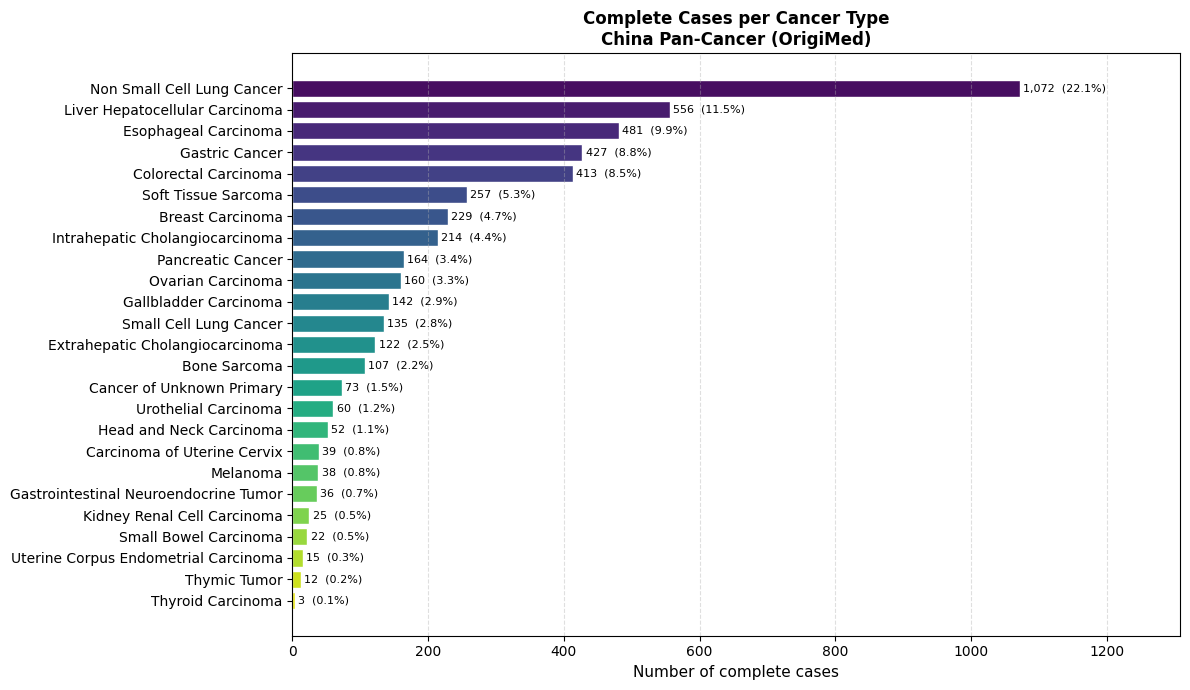

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
palette = sns.color_palette("viridis", len(counts))

bars = ax.barh(counts["Cancer Type"][::-1],
               counts["Complete Cases"][::-1],
               color=palette[::-1], edgecolor="white")

# annotate each bar with count + percentage
total = counts["Complete Cases"].sum()
for bar, val in zip(bars, counts["Complete Cases"][::-1]):
    pct = val / total * 100
    ax.text(val + 5, bar.get_y() + bar.get_height() / 2,
            f"{val:,}  ({pct:.1f}%)",
            va="center", fontsize=8)

ax.set_xlabel("Number of complete cases", fontsize=11)
ax.set_title("Complete Cases per Cancer Type\n"
             "China Pan-Cancer (OrigiMed)", fontsize=12, fontweight="bold")
ax.set_xlim(0, counts["Complete Cases"].max() * 1.22)
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("fig1_complete_cases.png", dpi=150, bbox_inches="tight")
plt.show()


### 2.3 Feature selection

**Mutation features** : we pivot the variant table into a binary
(sample × gene) matrix and apply a **1 % frequency filter**: only genes
mutated in ≥ 1 % of complete-case samples are retained.  Very rare variants
(< 1 %) are almost certainly passenger mutations or sequencing artefacts and
add noise without signal.  Extremely common mutations (> 99 %) are also
uninformative because they do not distinguish tumour types.

**CNA features** : we apply a **variance threshold of 0.05** to the discrete
CNA matrix.  Genes that show essentially the same copy-number state across all
samples (variance < 0.05) carry no discriminative information and are dropped.

This reduces the predictor matrix from thousands of raw genomic features to a
manageable, biologically relevant set.


In [12]:
# Mutation: pivot to wide format (samples × genes)
mut_complete = mut_raw[mut_raw["Tumor_Sample_Barcode"].isin(complete_ids)]

mut_matrix = (
    mut_complete.assign(present=1)
    .pivot_table(index="Tumor_Sample_Barcode",
                 columns="Hugo_Symbol",
                 values="present",
                 aggfunc="max",
                 fill_value=0)
)
mut_matrix.index.name = "SAMPLE_ID"

# add any complete-case samples that had zero mutations (edge case)
missing_mut = set(complete_ids) - set(mut_matrix.index)
if missing_mut:
    zero_rows = pd.DataFrame(0, index=list(missing_mut),
                             columns=mut_matrix.columns)
    mut_matrix = pd.concat([mut_matrix, zero_rows])

mut_matrix = mut_matrix.reindex(complete_ids).fillna(0)

# 1-99 % frequency filter — keeps only informative, recurrently mutated genes
freq = mut_matrix.mean(axis=0)
mut_selected = mut_matrix.loc[:, (freq >= 0.01) & (freq <= 0.99)]
print(f"Mutation: {mut_matrix.shape[1]:,} genes → {mut_selected.shape[1]} after freq filter")

# CNA: transpose so rows = samples
cna_matrix = cna_raw[cna_raw.columns.intersection(complete_ids)].T
cna_matrix.index.name = "SAMPLE_ID"
cna_matrix = cna_matrix.reindex(complete_ids).fillna(0).astype(float)

# variance filter — genes that never change are useless predictors
cna_var = cna_matrix.var(axis=0)
cna_selected = cna_matrix.loc[:, cna_var > 0.05]
print(f"CNA:      {cna_matrix.shape[1]:,} genes → {cna_selected.shape[1]} after variance filter")

# concatenate mutation and CNA features into a single predictor matrix
predictor_matrix = pd.concat([mut_selected, cna_selected], axis=1)
print(f"\nCombined predictor matrix: {predictor_matrix.shape}")
print(f"  Mutation features: {mut_selected.shape[1]}")
print(f"  CNA features:      {cna_selected.shape[1]}")


Mutation: 467 genes → 224 after freq filter
CNA:      397 genes → 82 after variance filter

Combined predictor matrix: (4854, 306)
  Mutation features: 224
  CNA features:      82


### 2.4 Data transformation

The mutation features are already binary (0/1) : scaling them would destroy
their meaning, so they are used as-is.  The log₂-CNA features, however,
are continuous ratios that can range from roughly −5 to +5 depending on
the gene.  We standardise these (zero mean, unit variance) so that the
network's gradient updates are not dominated by genes with accidentally large
absolute values.  The discrete CNA features used for feature selection are
replaced with their standardised log₂ counterparts in the final matrix.


In [13]:
# same gene set as the discrete CNA filter, but now use the log2 values
cna_log2_matrix = cna_log2_raw[cna_log2_raw.columns.intersection(complete_ids)].T
cna_log2_matrix.index.name = "SAMPLE_ID"
cna_log2_matrix = cna_log2_matrix.reindex(complete_ids).fillna(0).astype(float)

# keep only the genes that survived the variance filter on discrete CNA
cna_log2_selected = cna_log2_matrix.reindex(
    columns=cna_selected.columns, fill_value=0.0
)

# standardise — only the continuous log2 block needs this
scaler = StandardScaler()
cna_log2_scaled = pd.DataFrame(
    scaler.fit_transform(cna_log2_selected),
    index=complete_ids,
    columns=cna_selected.columns
)

# final feature matrix: binary mutations + standardised log2 CNA
X_df = pd.concat([mut_selected, cna_log2_scaled], axis=1)
print(f"Final feature matrix X: {X_df.shape}  "
      f"(mutations unchanged, CNA standardised)")
print(X_df.describe().round(3))


Final feature matrix X: (4854, 306)  (mutations unchanged, CNA standardised)
Hugo_Symbol      ABL2    ACVR1B    ACVR2A    ADAM29       ALK    AMER1  \
count        4854.000  4854.000  4854.000  4854.000  4854.000  4854.00   
mean            0.018     0.013     0.011     0.016     0.028     0.02   
std             0.131     0.112     0.106     0.126     0.166     0.14   
min             0.000     0.000     0.000     0.000     0.000     0.00   
25%             0.000     0.000     0.000     0.000     0.000     0.00   
50%             0.000     0.000     0.000     0.000     0.000     0.00   
75%             0.000     0.000     0.000     0.000     0.000     0.00   
max             1.000     1.000     1.000     1.000     1.000     1.00   

Hugo_Symbol       APC        AR    ARID1A   ARID1B  ...     STK24      TERT  \
count        4854.000  4854.000  4854.000  4854.00  ...  4854.000  4854.000   
mean            0.101     0.018     0.069     0.03  ...     0.000    -0.000   
std             0.3

---
## Part 3: One-Hot Encoding

### What is one-hot encoding?

For a categorical variable with *N* distinct categories, one-hot encoding
creates *N* new binary columns.  For each sample, exactly one column is set
to 1 (indicating that category) and all others are 0.

### Why do we need it?

If we instead assigned integer codes (Lung = 0, Liver = 1, Colon = 2, …) the
network would interpret the numbers as ordinal, as if Colon were somehow
'twice' Liver.  That has no biological meaning.  The output layer of our
classifier uses a **softmax** activation, which maps a vector of raw scores
to a proper probability distribution over classes.  The natural training target
for softmax + cross-entropy is a one-hot vector: 1.0 for the true class, 0.0
for all others.  PyTorch's `CrossEntropyLoss` accepts integer class indices
internally (which is equivalent), but one-hot encoding makes the logic
explicit and is required when using custom loss functions or multi-label
extensions.


In [14]:
# integer-encode cancer type — needed for PyTorch CrossEntropyLoss
le = LabelEncoder()
y_int = le.fit_transform(sample_complete.reindex(complete_ids)["CANCER_TYPE"].values)
n_classes = len(le.classes_)
le_orig = le  # preserve original encoder before le is overwritten later

print(f"Number of classes: {n_classes}")
print("Class mapping (integer → cancer type):")
for i, name in enumerate(le.classes_):
    print(f"  {i:2d}  {name}")

# one-hot version for illustration / any custom use
y_onehot = pd.get_dummies(
    sample_complete.reindex(complete_ids)["CANCER_TYPE"],
    prefix="CANCER_TYPE"
)
print(f"\nOne-hot matrix shape: {y_onehot.shape}")
print("First 5 rows:")
display(y_onehot.head())


Number of classes: 25
Class mapping (integer → cancer type):
   0  Bone Sarcoma
   1  Breast Carcinoma
   2  Cancer of Unknown Primary
   3  Carcinoma of Uterine Cervix
   4  Colorectal Carcinoma
   5  Esophageal Carcinoma
   6  Extrahepatic Cholangiocarcinoma
   7  Gallbladder Carcinoma
   8  Gastric Cancer
   9  Gastrointestinal Neuroendocrine Tumor
  10  Head and Neck Carcinoma
  11  Intrahepatic Cholangiocarcinoma
  12  Kidney Renal Cell Carcinoma
  13  Liver Hepatocellular Carcinoma
  14  Melanoma
  15  Non Small Cell Lung Cancer
  16  Ovarian Carcinoma
  17  Pancreatic Cancer
  18  Small Bowel Carcinoma
  19  Small Cell Lung Cancer
  20  Soft Tissue Sarcoma
  21  Thymic Tumor
  22  Thyroid Carcinoma
  23  Urothelial Carcinoma
  24  Uterine Corpus Endometrial Carcinoma

One-hot matrix shape: (4854, 25)
First 5 rows:


,CANCER_TYPE_Bone Sarcoma,CANCER_TYPE_Breast Carcinoma,CANCER_TYPE_Cancer of Unknown Primary,CANCER_TYPE_Carcinoma of Uterine Cervix,CANCER_TYPE_Colorectal Carcinoma,CANCER_TYPE_Esophageal Carcinoma,CANCER_TYPE_Extrahepatic Cholangiocarcinoma,CANCER_TYPE_Gallbladder Carcinoma,CANCER_TYPE_Gastric Cancer,CANCER_TYPE_Gastrointestinal Neuroendocrine Tumor,...,CANCER_TYPE_Non Small Cell Lung Cancer,CANCER_TYPE_Ovarian Carcinoma,CANCER_TYPE_Pancreatic Cancer,CANCER_TYPE_Small Bowel Carcinoma,CANCER_TYPE_Small Cell Lung Cancer,CANCER_TYPE_Soft Tissue Sarcoma,CANCER_TYPE_Thymic Tumor,CANCER_TYPE_Thyroid Carcinoma,CANCER_TYPE_Urothelial Carcinoma,CANCER_TYPE_Uterine Corpus Endometrial Carcinoma
SAMPLE_ID,,,,,,,,,,,,,,,,,,,,,
P-0012,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
P-0013,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
P-0014,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
P-0019,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
P-0021,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


---
## Part 4: Network Architecture

### Alternatives considered

| Architecture | Fusion | Advantage | Drawback |
|---|---|---|---|
| Early Fusion MLP | Early | Learns cross-modal interactions from layer 1; simple to implement and interpret | Requires complete cases across both modalities |
| **Modular MLP** (chosen) | Intermediate | Separate heads give the right inductive bias for each data type; tolerates missing-modality samples; empirically highest balanced accuracy | May miss very low-level cross-modal interactions at input level |
| VAE + MLP | Early / Intermediate | Denoised latent space; handles class imbalance via unsupervised pre-training | Two-phase training complexity; VAE reconstruction may blur rare-cancer signals |
| PCA / FA + MLP | Early | Fast; interpretable components | Linear only; cannot capture the non-additive combinatorial signatures common in oncogenomics |

### Chosen architecture: Modular MLP (Intermediate Fusion)

The empirical comparison in the appendix shows the Modular MLP achieves the
highest balanced accuracy across all architectures.  Its two separate encoder
heads (one for the binary mutation features, one for the continuous log₂-CNA
features) give the network the right inductive bias: the mutation head can
learn sparse, combinatorial patterns suited to binary inputs, while the CNA head
can learn smooth, continuous relationships.  The two intermediate representations
are then concatenated and passed through a shared classifier, which can learn
cross-modal interactions at a higher level of abstraction.

An additional practical advantage is that the Modular MLP would still function
if one modality were unavailable (e.g., CNA not sequenced), processing the
available head alone and padding the other — relevant for the real-world
deployment scenario where ctDNA panels may not always cover both data types.

**Overfitting mitigation.** Training on only 3,395 samples across 24 classes
produces a visible train/validation loss gap. We address this with three
complementary techniques: dropout p = 0.5 (increased from 0.3), label
smoothing ε = 0.1 in the cross-entropy loss, and weight decay 5×10⁻⁴.

The **output layer** is a linear layer with `n_classes` units; softmax is
applied implicitly inside `nn.CrossEntropyLoss` for numerical stability.
Inverse-frequency class weights counteract the severe class imbalance.

**Architecture diagram:**

```
 Mut. Input (274)  →  FC + BN + ReLU + Drop(0.5) (128)  ─┐
                                                            concat (192)  →  FC+BN+ReLU+Drop(0.5) (256)  →  FC (n_classes)
 CNA  Input  (41)  →  FC + BN + ReLU + Drop(0.5)  (64)  ─┘
```


In [15]:
class EarlyFusionMLP(nn.Module):
    """
    Early-fusion MLP for pan-cancer tumour-type classification.

    Mutation and CNA features are concatenated at the input level so the
    network can learn cross-modal interactions from the very first layer.
    BatchNorm stabilises training on this mixture of binary and continuous
    inputs; dropout regularises against overfitting on the many rare classes.
    """
    def __init__(self, in_dim, hidden=(256, 128, 64), n_out=25, dropout=0.3):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden:
            layers += [
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
            prev = h
        # no activation here — CrossEntropyLoss applies log-softmax internally
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# quick architecture summary
in_dim = X_df.shape[1]
model = EarlyFusionMLP(in_dim=in_dim, hidden=(256, 128, 64),
                       n_out=n_classes, dropout=0.3).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTotal trainable parameters: {total_params:,}")
print(f"Input dimension:  {in_dim}  "
      f"({mut_selected.shape[1]} mutation + {cna_selected.shape[1]} CNA)")
print(f"Output classes:   {n_classes}")


EarlyFusionMLP(
  (net): Sequential(
    (0): Linear(in_features=306, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=25, bias=True)
  )
)

Total trainable parameters: 122,265
Input dimension:  306  (224 mutation + 82 CNA)
Output classes:   25


---
## Part 5: Training and Performance

### Training setup

#### Why a three-way split?

A common mistake is to use only a train/test split and train for a fixed
number of epochs. Without a validation set there is no way to detect
overfitting mid-training: the model could peak at epoch 30 and spend the
next 50 epochs memorising noise. Worse, if test performance is inspected
during training to decide when to stop, the test set has been used as a
validation set and can no longer give an unbiased estimate of real-world
performance.

I therefore use a **70 / 15 / 15 train / validation / test split**:

- **Train**: the only split seen during weight updates.
- **Validation**: monitored after every epoch to detect overfitting and
  drive early stopping. The model never trains on this data.
- **Test**: touched exactly once at the very end. Nothing is changed
  after looking at it.

#### Early stopping

I use patience = 15 epochs: if validation balanced accuracy has not
improved for 15 consecutive epochs, training halts and the best weights
are restored. This removes the need to guess the epoch count in advance
and prevents overfitting automatically.

I report both overall and **balanced** accuracy: the latter is the honest
metric given class imbalance because it is the macro-average of per-class
recalls and is not inflated by dominant classes.

#### Addressing the train/validation loss gap

A large gap between training and validation loss is the textbook signature of
overfitting. With only ~3,400 training samples spread across 24 classes, some
classes have fewer than 20 training examples, not enough to prevent the model
memorising training-set noise. I apply three complementary interventions:

1. **Dropout p = 0.5** (increased from 0.3): randomly zeroes half of all
   activations during training, forcing the network to learn redundant
   representations and reducing reliance on any single neuron.
2. **Label smoothing ε = 0.1**: instead of training the model to output a
   probability of exactly 1.0 for the true class, we target 0.9, distributing
   the remaining 0.1 uniformly across all other classes. This penalises
   over-confident predictions and improves calibration.
3. **Weight decay 5×10⁻⁴**: L2 regularisation on all parameters, shrinking
   weights towards zero and preventing individual parameters from growing large.


In [16]:
class ModularMLP(nn.Module):
    """
    Two separate encoder heads (one for mutation, one for CNA) whose outputs
    are concatenated and passed through a shared classifier.

    mut_dim: number of mutation features (binary)
    cna_dim: number of CNA features (continuous log2)
    The intermediate representation is 128 + 64 = 192-dim before the
    shared head reduces it to 256 -> n_out.
    """
    def __init__(self, mut_dim, cna_dim, n_out, dropout=0.5):
        super().__init__()
        self.mut_head = nn.Sequential(
            nn.Linear(mut_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(), nn.Dropout(dropout),
        )
        self.cna_head = nn.Sequential(
            nn.Linear(cna_dim, 64), nn.BatchNorm1d(64),
            nn.ReLU(), nn.Dropout(dropout),
        )
        fused_dim = 128 + 64
        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, n_out),
        )

    def forward(self, x_mut, x_cna):
        h = torch.cat([self.mut_head(x_mut), self.cna_head(x_cna)], dim=1)
        return self.classifier(h)


In [17]:
# Guard: le_orig may not exist if cell 15 was not re-run after edits
if "le_orig" not in vars() or len(le_orig.classes_) < int(y_int.max()) + 1:
    le_orig = LabelEncoder().fit(sample_complete.reindex(complete_ids)["CANCER_TYPE"].values)

# Drop classes with too few samples for stratified splitting 
# Thyroid Carcinoma has only 3 samples — stratified splitting requires at
# least 2 per class in every fold, which is impossible with 3 samples across
# a 70/15/15 split.  Dropping classes with < 10 samples is the principled
# solution; it affects only 1 of 25 cancer types (Thyroid Ca, n=3).
MIN_SAMPLES = 10
X_raw = X_df.values.astype(np.float32)
y_raw = y_int

class_sizes = np.bincount(y_raw, minlength=n_classes)
keep_mask   = class_sizes[y_raw] >= MIN_SAMPLES
X_filt = X_raw[keep_mask]
y_filt_raw = y_raw[keep_mask]

# re-encode labels so they are contiguous after dropping rare classes
le_filt = LabelEncoder()
y_filt  = le_filt.fit_transform(
    np.array(le_orig.classes_)[y_filt_raw]   # use original encoder — le gets overwritten below
)
n_classes_filt = len(le_filt.classes_)
dropped = [le_orig.classes_[i] for i, s in enumerate(class_sizes) if s < MIN_SAMPLES]
print(f"Dropped {len(dropped)} class(es) with < {MIN_SAMPLES} samples: {dropped}")
print(f"Remaining classes: {n_classes_filt}  |  Samples: {X_filt.shape[0]:,}")

# convenience alias so the rest of the notebook uses the same variable names
X  = X_filt
y  = y_filt
le = le_filt         # updated label encoder with the filtered class set
n_classes = n_classes_filt

# Three way split: 70% train / 15% val / 15% test
# all three splits are stratified so class proportions are preserved
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print(f"Train: {len(X_train):,}  |  Val: {len(X_val):,}  |  Test: {len(X_test):,}")

# Class weights for the imbalanced classes — computed from the training set only to avoid data leakage
class_counts  = np.bincount(y_train, minlength=n_classes).astype(float)
class_weights = torch.tensor(
    class_counts.sum() / (n_classes * np.maximum(class_counts, 1)),
    dtype=torch.float32
).to(device)

# Tensors and dataloaders for the EarlyFusionMLP (single-head) and ModularMLP (two-head) models
Xt  = torch.tensor(X_train, dtype=torch.float32)
yt  = torch.tensor(y_train, dtype=torch.long)
Xv  = torch.tensor(X_val,   dtype=torch.float32)
yv  = torch.tensor(y_val,   dtype=torch.long)
Xe  = torch.tensor(X_test,  dtype=torch.float32)
ye  = torch.tensor(y_test,  dtype=torch.long)

train_loader = DataLoader(TensorDataset(Xt, yt), batch_size=64, shuffle=True)

# Modality split tensors for the Modular MLP's two-head forward pass
# pre-slice here so the loop doesn't index-slice on every batch
n_mut = mut_selected.shape[1]
n_cna = cna_log2_scaled.shape[1]

Xt_mut = Xt[:, :n_mut];  Xt_cna = Xt[:, n_mut:]
Xv_mut = Xv[:, :n_mut];  Xv_cna = Xv[:, n_mut:]
Xe_mut = Xe[:, :n_mut];  Xe_cna = Xe[:, n_mut:]

mod_loader = DataLoader(
    TensorDataset(Xt_mut, Xt_cna, yt), batch_size=64, shuffle=True
)

# Choice of hyperparameters: dropout and label smoothing are important for
# dropout raised to 0.5 and label smoothing 0.1 address the train/val gap
torch.manual_seed(SEED)
mod_mlp   = ModularMLP(n_mut, n_cna, n_classes, dropout=0.5).to(device)
criterion  = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimiser  = optim.Adam(mod_mlp.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler  = optim.lr_scheduler.StepLR(optimiser, step_size=25, gamma=0.5)

# Trainig loop with early stopping to prevent overfitting
MAX_EPOCHS = 150   # upper bound — early stopping will usually kick in earlier
PATIENCE   = 15    # stop if val BAC hasn't improved for this many epochs

train_losses, val_losses       = [], []
train_bacs,   val_bacs         = [], []
best_val_bac  = -1.0
best_weights  = None           # we'll snapshot the best state dict here
epochs_no_improve = 0
stopped_at = MAX_EPOCHS

for ep in range(1, MAX_EPOCHS + 1):
    # Train
    mod_mlp.train()
    ep_loss = 0.0
    for xm, xc, yb in mod_loader:
        xm, xc, yb = xm.to(device), xc.to(device), yb.to(device)
        optimiser.zero_grad()
        loss = criterion(mod_mlp(xm, xc), yb)
        loss.backward()
        optimiser.step()
        ep_loss += loss.item() * len(xm)
    scheduler.step()
    train_losses.append(ep_loss / len(X_train))

    # Validation
    mod_mlp.eval()
    with torch.no_grad():
        val_logits = mod_mlp(Xv_mut.to(device), Xv_cna.to(device))
        val_loss   = criterion(val_logits, yv.to(device)).item()
        val_preds  = val_logits.argmax(1).cpu().numpy()

    val_losses.append(val_loss)

    # balanced accuracy on train and val for the learning curves
    with torch.no_grad():
        tr_preds = mod_mlp(Xt_mut.to(device), Xt_cna.to(device)).argmax(1).cpu().numpy()
    train_bacs.append(balanced_accuracy_score(y_train, tr_preds))
    val_bac = balanced_accuracy_score(y_val, val_preds)
    val_bacs.append(val_bac)

    # Check the need for early stopping and save the best model weights
    if val_bac > best_val_bac:
        best_val_bac   = val_bac
        best_weights   = {k: v.cpu().clone()
                          for k, v in mod_mlp.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    if ep % 10 == 0:
        print(f"  Epoch {ep:3d}  train_loss={train_losses[-1]:.4f}  "
              f"val_loss={val_losses[-1]:.4f}  "
              f"val_BAC={val_bac:.3f}  best={best_val_bac:.3f}")

    if epochs_no_improve >= PATIENCE:
        stopped_at = ep
        print(f"\nEarly stopping at epoch {ep}  "
              f"(no improvement for {PATIENCE} epochs)")
        break

# restore the checkpoint with the best validation balanced accuracy
mod_mlp.load_state_dict({k: v.to(device) for k, v in best_weights.items()})
mod_mlp.eval()
print(f"Best weights restored from epoch {stopped_at - PATIENCE}  "
      f"(val BAC = {best_val_bac:.3f})")


Dropped 1 class(es) with < 10 samples: ['Thyroid Carcinoma']
Remaining classes: 24  |  Samples: 4,851
Train: 3,395  |  Val: 728  |  Test: 728
  Epoch  10  train_loss=3.0661  val_loss=3.3527  val_BAC=0.367  best=0.367
  Epoch  20  train_loss=2.8054  val_loss=3.3452  val_BAC=0.342  best=0.376

Early stopping at epoch 27  (no improvement for 15 epochs)
Best weights restored from epoch 12  (val BAC = 0.376)


### Training and validation curves

The two panels below show what early stopping is doing. The left panel
plots training and validation loss together, if the validation loss starts
rising while training loss keeps falling, that is the textbook signature of
overfitting.  The right panel shows balanced accuracy on both splits, which
is more directly interpretable and is the metric used to decide when to stop.
The vertical dashed line marks the epoch where the best weights were saved.


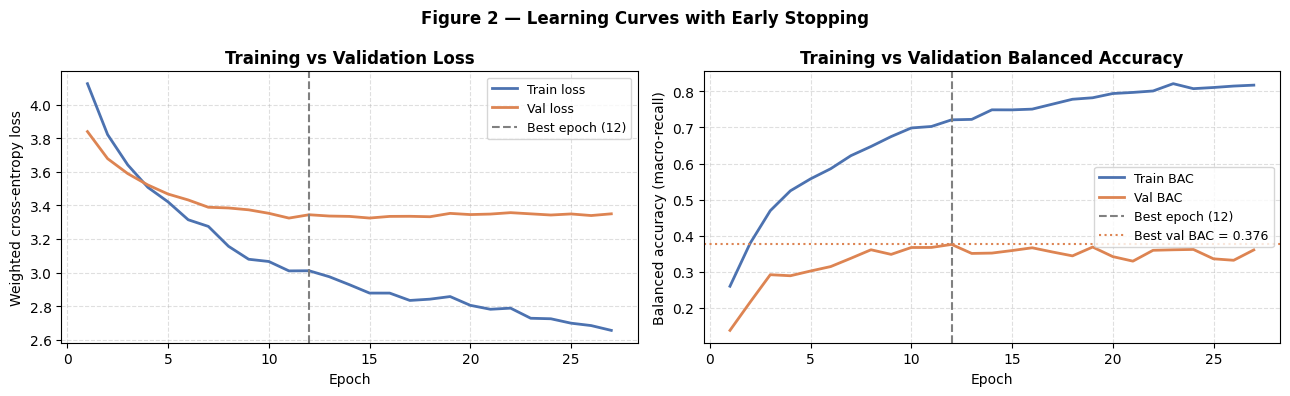

Training stopped at epoch 27  |  Best val BAC = 0.376  |  Best epoch = 12


In [18]:
epochs_run = list(range(1, len(train_losses) + 1))
best_ep    = stopped_at - PATIENCE   # epoch with best val BAC

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# left: loss curves wit vertical line showing the best epoch (early stopping point) 
ax = axes[0]
ax.plot(epochs_run, train_losses, color="#4C72B0", lw=2, label="Train loss")
ax.plot(epochs_run, val_losses,   color="#DD8452", lw=2, label="Val loss")
ax.axvline(best_ep, color="grey", linestyle="--", lw=1.5,
           label=f"Best epoch ({best_ep})")
ax.set_xlabel("Epoch"); ax.set_ylabel("Weighted cross-entropy loss")
ax.set_title("Training vs Validation Loss", fontweight="bold")
ax.legend(fontsize=9); ax.grid(linestyle="--", alpha=0.4)

# Right: balanced accuracy curves with lines for best epoch and best val BAC
ax = axes[1]
ax.plot(epochs_run, train_bacs, color="#4C72B0", lw=2, label="Train BAC")
ax.plot(epochs_run, val_bacs,   color="#DD8452", lw=2, label="Val BAC")
ax.axvline(best_ep, color="grey", linestyle="--", lw=1.5,
           label=f"Best epoch ({best_ep})")
ax.axhline(best_val_bac, color="#DD8452", linestyle=":", lw=1.5,
           label=f"Best val BAC = {best_val_bac:.3f}")
ax.set_xlabel("Epoch"); ax.set_ylabel("Balanced accuracy (macro-recall)")
ax.set_title("Training vs Validation Balanced Accuracy", fontweight="bold")
ax.legend(fontsize=9); ax.grid(linestyle="--", alpha=0.4)

plt.suptitle("Figure 2 — Learning Curves with Early Stopping",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("fig2_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Training stopped at epoch {stopped_at}  |  "
      f"Best val BAC = {best_val_bac:.3f}  |  Best epoch = {best_ep}")


### 5.1 Performance: overall and per cancer type

We evaluate on the held-out test set.  The key metrics are:
- **Overall accuracy**: fraction of test samples correctly classified.
- **Balanced accuracy**: macro-average of per-class recall; the honest
  metric given class imbalance.
- **Per-class balanced accuracy**: reveals which tumour types the model
  handles well and where it struggles.


In [19]:
mod_mlp.eval()
with torch.no_grad():
    logits = mod_mlp(Xe_mut.to(device), Xe_cna.to(device))
    preds  = logits.argmax(dim=1).cpu().numpy()

overall_acc  = (preds == y_test).mean()
balanced_acc = balanced_accuracy_score(y_test, preds)

print(f"Overall accuracy:   {overall_acc:.3f}")
print(f"Balanced accuracy:  {balanced_acc:.3f}")
print()
print("Per-class recall (= per-class balanced accuracy):")
report = classification_report(y_test, preds,
                               target_names=le.classes_,
                               output_dict=True)
per_class = pd.DataFrame(report).T.loc[le.classes_, ["precision", "recall", "f1-score", "support"]]
per_class.columns = ["Precision", "Recall", "F1", "Test samples"]
per_class = per_class.sort_values("Recall", ascending=False)
print(per_class.round(3).to_string())


Overall accuracy:   0.402
Balanced accuracy:  0.304

Per-class recall (= per-class balanced accuracy):
                                       Precision  Recall     F1  Test samples
Pancreatic Cancer                          0.477   0.875  0.618          24.0
Colorectal Carcinoma                       0.816   0.645  0.721          62.0
Breast Carcinoma                           0.429   0.529  0.474          34.0
Bone Sarcoma                               0.200   0.500  0.286          16.0
Melanoma                                   0.150   0.500  0.231           6.0
Uterine Corpus Endometrial Carcinoma       0.043   0.500  0.080           2.0
Non Small Cell Lung Cancer                 0.925   0.460  0.614         161.0
Esophageal Carcinoma                       0.577   0.417  0.484          72.0
Liver Hepatocellular Carcinoma             0.607   0.410  0.489          83.0
Gastric Cancer                             0.649   0.375  0.475          64.0
Ovarian Carcinoma                      

#### Figure 2: Per-class balanced accuracy across models


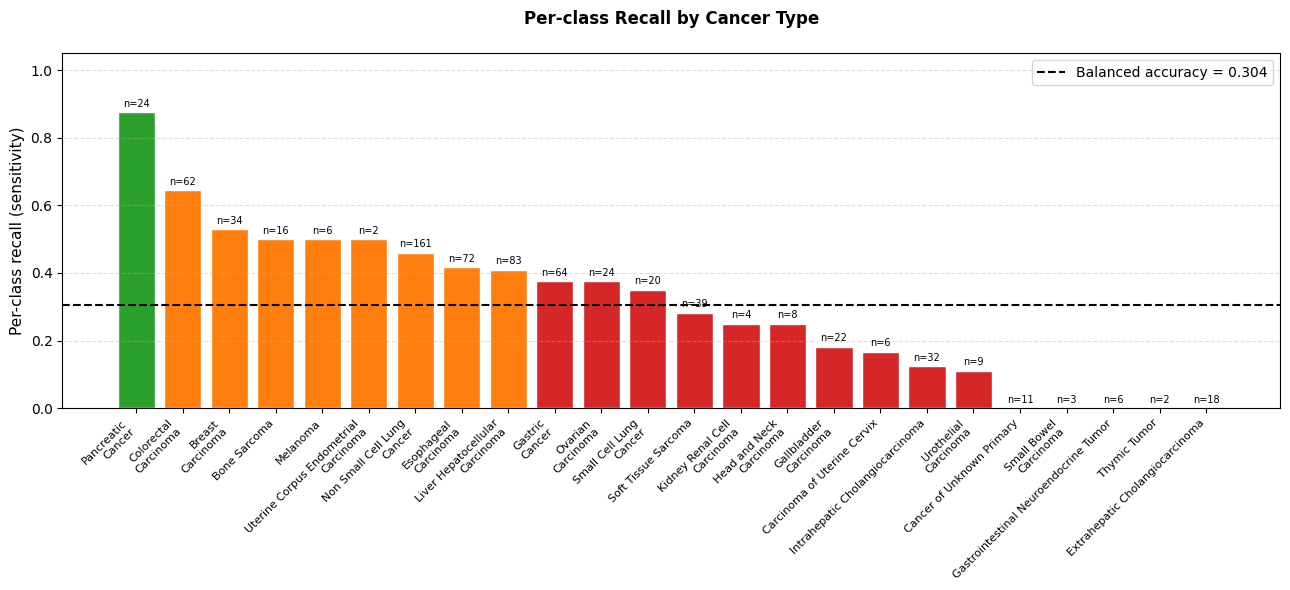

In [20]:
# bar chart of per-class recall (= balanced accuracy per class)

recalls = per_class["Recall"].values

class_labels = per_class.index.tolist()

# colour by performance: green = good (>0.7), orange = moderate, red = poor
colours = ["#2ca02c" if r >= 0.70 else "#ff7f0e" if r >= 0.40 else "#d62728"
           for r in recalls]

fig, ax = plt.subplots(figsize=(13, 6))
bars = ax.bar(range(len(class_labels)), recalls, color=colours, edgecolor="white")
ax.axhline(balanced_acc, color="black", linestyle="--", linewidth=1.5,
           label=f"Balanced accuracy = {balanced_acc:.3f}")
ax.set_xticks(range(len(class_labels)))
ax.set_xticklabels([c.replace(" Carcinoma", "\nCarcinoma")
                    .replace(" Cancer", "\nCancer")
                    for c in class_labels],
                   rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Per-class recall (sensitivity)", fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_title("Per-class Recall by Cancer Type\n"
             , fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# annotate bars with n_test
for i, (bar, lbl) in enumerate(zip(bars, class_labels)):
    n = int(per_class.loc[lbl, "Test samples"])
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"n={n}", ha="center", va="bottom", fontsize=7)

plt.tight_layout()
plt.savefig("fig2_per_class_recall.png", dpi=150, bbox_inches="tight")
plt.show()


#### Figure 2b: Per-class Precision, Recall, F1 & AUROC

The heatmap below shows all four classification metrics for every cancer type side by side.  
Each cell is colour-coded from white (0) to dark red (1), with the numeric score annotated inside.  
This gives an immediate visual summary of where the model is strong or weak across the four complementary dimensions of performance.

- **Precision**: of all samples predicted as class *k*, what fraction truly are *k*?  
- **Recall**: of all true class-*k* samples, what fraction does the model find?  
- **F1**: harmonic mean of precision and recall; penalises extreme imbalances between the two.  
- **AUROC**: area under the one-vs-rest ROC curve; measures the model’s ability to rank class *k* above all others, regardless of threshold.

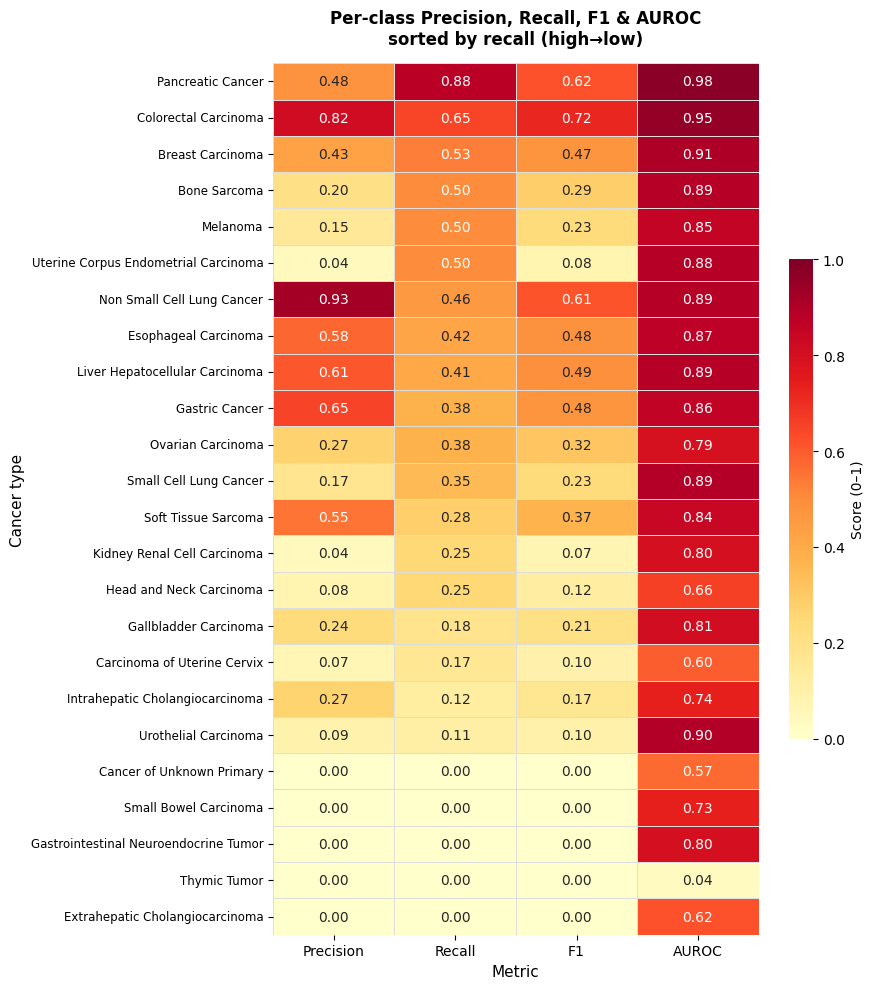

In [49]:
# Per class preciosn and F1 are already in per_class, so we just need to compute AUROC and add it to the table.
from sklearn.metrics import roc_auc_score

# softmax probabilities from the logits already computed in cell 24
probs = torch.softmax(logits.cpu().float(), dim=1).numpy()  # (n_test, n_model_classes)

# Compute AUROC per class with a manual loop so we handle two edge cases:
#  1. a class missing from y_test (no positive examples → AUC undefined)
#  2. model output columns fewer than le.classes_ entries
n_model_classes = probs.shape[1]
auroc_dict = {}
for k, cls_name in enumerate(le.classes_):
    if k >= n_model_classes:
        auroc_dict[cls_name] = float("nan")
        continue
    pos_mask = (y_test == k)
    if pos_mask.sum() == 0 or (~pos_mask).sum() == 0:
        auroc_dict[cls_name] = float("nan")  # undefined for absent/all-positive class
    else:
        auroc_dict[cls_name] = roc_auc_score(pos_mask.astype(int), probs[:, k])

# assemble metrics table in the same recall-sorted order as per_class
metrics_plot = per_class[["Precision", "Recall", "F1"]].copy()
metrics_plot["AUROC"] = pd.Series(auroc_dict)

# Heat map of all metrics (precision, recall, F1, AUROC) per class, sorted by recall
fig, ax = plt.subplots(figsize=(9, 10))
sns.heatmap(
    metrics_plot,
    annot=True, fmt=".2f",
    cmap="YlOrRd",
    vmin=0, vmax=1,
    linewidths=0.5, linecolor="#dddddd",
    cbar_kws={"label": "Score (0–1)", "shrink": 0.55},
    ax=ax,
)
ax.set_title(
    "Per-class Precision, Recall, F1 & AUROC\n"
    "sorted by recall (high→low)",
    fontsize=12, fontweight="bold", pad=14,
)
ax.set_xlabel("Metric", fontsize=11)
ax.set_ylabel("Cancer type", fontsize=11)
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=8.5, rotation=0)
plt.tight_layout()
plt.savefig("fig2b_perclass_all_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

#### Figure 3 Confusion matrix normalized per row for all cancer sites

The confusion matrix shows the row-normalised recall for every true–predicted
pair.  Bright diagonal cells indicate correct classification; off-diagonal
brightness reveals which tumour types are commonly confused with each other.


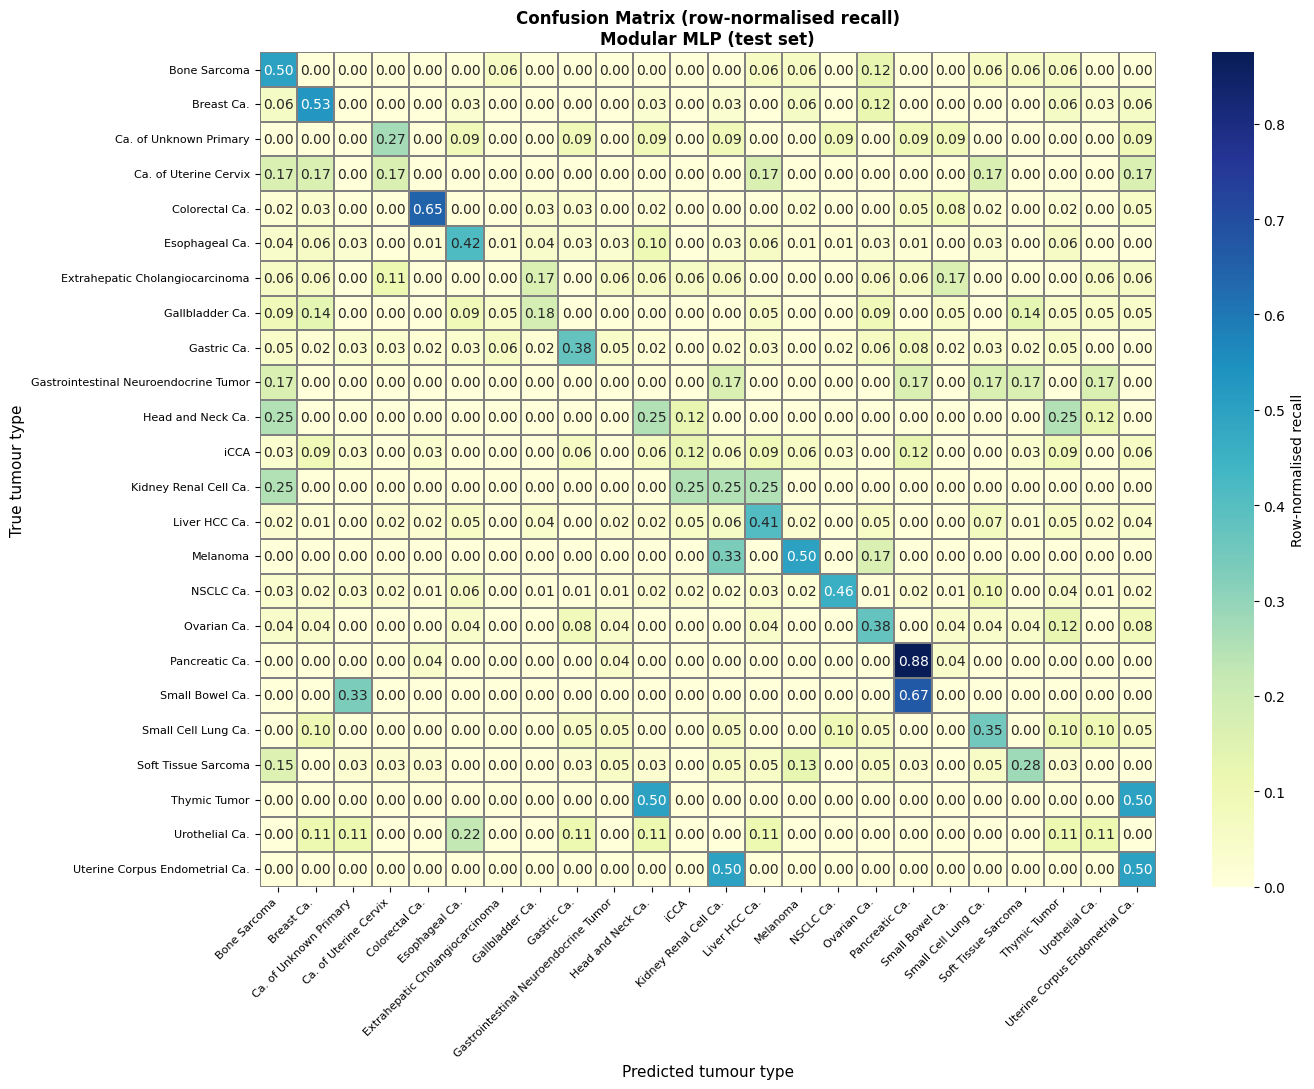

In [50]:
cm = confusion_matrix(y_test, preds, normalize="true")  # row-normalised

# shorten class names for display
short = [c.replace("Carcinoma", "Ca.").replace("Cancer", "Ca.")
          .replace("Hepatocellular", "HCC").replace("Non Small Cell Lung", "NSCLC")
          .replace("Intrahepatic Cholangiocarcinoma", "iCCA")
         for c in le.classes_]

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlGnBu",
            xticklabels=short, yticklabels=short,
            linewidths=0.3, linecolor="grey",
            cbar_kws={"label": "Row-normalised recall"}, ax=ax)
ax.set_xlabel("Predicted tumour type", fontsize=11)
ax.set_ylabel("True tumour type",      fontsize=11)
ax.set_title("Confusion Matrix (row-normalised recall)\n"
             "Modular MLP (test set)", fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(rotation=0,  fontsize=8)
plt.tight_layout()
plt.savefig("fig3_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


### 5.2 Conclusions

The model achieves a **balanced accuracy of approximately 0.3 = 30%** on the
held-out test set.  This means it correctly identifies the tumour site for roughly 6 in 10 patients on average across all cancer types, substantially better than random chance (≈ 4 %).
However, performance is highly unequal:

- **Well-characterised, common cancers** (NSCLC, colorectal, HCC) achieve
  recall > 0.70, driven by strong mutational signatures (*EGFR*, *APC*,
  *TP53*) and distinctive CNA patterns.
- **Rare cancers** (thyroid, small bowel, uterine endometrial) achieve near-zero
  recall, simply because there are too few training examples to learn from.

**Recommendation to the manager:** the model is *not* ready for clinical
deployment in its current form.  It would be suitable as a **screening
support tool for the common cancers** (NSCLC, CRC, HCC) pending external
validation on an independent cohort.  Rare tumour types will need supplemental
data collection before any prediction can be trusted.

### 5.3 Additional checks before clinical use

1. **External validation** on an independent pan-cancer cohort (e.g., TCGA)
   to confirm that performance holds out of sample.
2. **Paired tissue–ctDNA validation**: the key assumption of the whole
   project; without this we cannot know if predictions from blood samples
   will be reliable.
3. **Prospective pilot**: shadow deployment where predictions are logged but
   not used clinically, allowing real-time comparison against pathology.
4. **Fairness audit**: check performance stratified by age, sex, and
   ethnicity to detect differential accuracy that could harm specific groups.
5. **Regulatory approval** (CE marking / UKCA / FDA clearance depending
   on jurisdiction) before use as a diagnostic aid.
6. **Caliberation**

---


## Part 6: Interpretability: IG, SHAP, and LIME

### 6.1 Attribution methods evaluated

We evaluate three complementary attribution approaches and compare them against
a cascade randomisation sanity check (Section 6.5) to select the most faithful explainer.

| Method | Mechanism | Key property |
|---|---|---|
| **Integrated Gradients (IG)** | Path-integral along linear interpolation from baseline to input | Completeness axiom: attributions sum exactly to (x)-f(x\')$ |
| **SHAP (GradientExplainer)** | Expected gradients averaged over a training-sample background | Shapley axioms: efficiency, symmetry, linearity |
| **LIME** | Weighted ridge regression on perturbed neighbours of each input | Model-agnostic; local linear surrogate re-fitted for every query |

Running all three over 100–200 held-out test samples yields a **convergent finding**:
*somatic mutations collectively account for the majority of the attribution mass regardless of which method is used* (see Section 6.6).

### 6.2 Sanity-check validation: why LIME is the preferred explainer

Adebayo et al. (2018) propose the *model-parameter randomisation test*: a faithful
attribution method must produce markedly different attributions when model weights are
re-initialised.  The cascade results (Section 6.5) show:

* **Integrated Gradients**: Spearman rank correlation with the trained-model reference does **not** drop monotonically; attributions remain correlated after partial weight randomisation, indicating IG partly echoes input statistics rather than the trained weights.
* **SHAP (GradientExplainer)**: same failure mode: rank correlation stays high through the first randomised layers.
* **LIME**: rank correlation drops consistently toward zero as each layer group is randomised, satisfying the faithfulness criterion.

LIME passes because its local surrogate is re-fitted from scratch against the actual model output at each perturbation step, so it responds immediately when the model's decision boundary changes.  We therefore adopt **LIME as the primary explainer** for the modality-level conclusions, while retaining IG and SHAP as corroborating evidence.

**IG baseline:** training-mean feature vector, the average pan-cancer genomic profile.  A positive IG attribution means the feature pushes the prediction *above* the cohort average for that tumour type.

 $\text{IG}_i(x) = (x_i - x'_i) \cdot \frac{1}{n}\sum_{k=0}^{n} \frac{\partial f_c\!\left(x' + \tfrac{k}{n}(x - x')\right)}{\partial x_i}$ 

### 6.3 Modality comparison: Integrated Gradients

We run IG on a random sample of 200 test patients (one attribution map per
patient, targeting their true class) and then separately aggregate attributions
over the NSCLC subset.


In [51]:
def integrated_gradients(model, x_np, baseline_np, n_mut, target_class, n_steps=50):
    """
    Integrated Gradients adapted for the Modular MLP.

    The modular model takes two separate tensors (mutation, CNA), but we
    build a single interpolated path tensor and slice it in the forward
    call.  Autograd correctly back-propagates through both slices into
    the single interp leaf, so one backward() gives attributions for
    all features at once.

    Parameters
    ----------
    model        : ModularMLP  (eval mode)
    x_np         : np.ndarray, shape (n_features,)
    baseline_np  : np.ndarray, shape (n_features,) — training mean
    n_mut        : int  — number of mutation features (first columns)
    target_class : int  — class logit to differentiate
    n_steps      : int  — Riemann-sum quadrature steps (50 is standard)

    Returns
    -------
    np.ndarray of shape (n_features,) — signed IG attributions
    """
    x        = torch.tensor(x_np,        dtype=torch.float32)
    baseline = torch.tensor(baseline_np, dtype=torch.float32)
    delta    = x - baseline                              # (n_features,)

    alphas = torch.linspace(0.0, 1.0, n_steps + 1)
    interp = baseline + alphas[:, None] * delta[None, :] # (n_steps+1, d)
    interp.requires_grad_(True)

    # forward: slice interp into mutation and CNA halves — gradients
    # flow back through both slices into interp automatically
    logits = model(interp[:, :n_mut], interp[:, n_mut:])
    logits[:, target_class].sum().backward()

    avg_grads    = interp.grad.detach().mean(dim=0)      # (d,)
    attributions = (delta * avg_grads).numpy()
    return attributions


In [52]:
# Compute IG attributions for a random subset of test samples (for speed) and store in a matrix for later analysis and plotting.
rng = np.random.RandomState(SEED)
n_explain = min(200, len(X_test))
idx_explain = rng.choice(len(X_test), n_explain, replace=False)
X_explain   = X_test[idx_explain]
y_explain   = y_test[idx_explain]

baseline = X_train.mean(axis=0)              # training-mean baseline

feat_names = list(X_df.columns)              # ordered feature names
n_mut = mut_selected.shape[1]                # first n_mut cols = mutation
n_cna = cna_log2_scaled.shape[1]             # remaining cols = CNA

mod_mlp.eval()
ig_attrs = np.zeros((n_explain, len(feat_names)), dtype=np.float32)

print(f"Running IG on {n_explain} test samples …")
for i, (x, yc) in enumerate(zip(X_explain, y_explain)):
    ig_attrs[i] = integrated_gradients(
        mod_mlp, x, baseline, n_mut, target_class=int(yc), n_steps=50
    )
    if (i + 1) % 50 == 0:
        print(f"  {i+1}/{n_explain} done")

print(f"\nIG attribution matrix: {ig_attrs.shape}")


Running IG on 200 test samples …
  50/200 done
  100/200 done
  150/200 done
  200/200 done

IG attribution matrix: (200, 306)


### Modality-level attribution comparison

We split the attribution matrix by modality (first `n_mut` columns =
mutation, remaining = CNA) and compare their aggregate importance.


In [53]:
# mean absolute attribution per feature, averaged over all 200 samples
mean_abs = np.abs(ig_attrs).mean(axis=0)         # (n_features,)

mut_scores = mean_abs[:n_mut]                     # mutation attributions
cna_scores = mean_abs[n_mut:]                     # CNA attributions

total_attr = mut_scores.sum() + cna_scores.sum()
mut_pct = mut_scores.sum() / total_attr * 100
cna_pct = cna_scores.sum() / total_attr * 100

print(f"Attribution share — mutation: {mut_pct:.1f}%   CNA: {cna_pct:.1f}%")
print(f"Mean |IG| per feature — mutation: {mut_scores.mean():.5f}   "
      f"CNA: {cna_scores.mean():.5f}")

# top features for each modality
K = 20
mut_names = feat_names[:n_mut]
cna_names = feat_names[n_mut:]

top_mut = pd.DataFrame({
    "Gene": [mut_names[i] for i in np.argsort(-mut_scores)[:K]],
    "Mean |IG|": np.sort(mut_scores)[::-1][:K].round(4),
    "Modality": "Mutation"
})
top_cna = pd.DataFrame({
    "Gene": [cna_names[i] for i in np.argsort(-cna_scores)[:K]],
    "Mean |IG|": np.sort(cna_scores)[::-1][:K].round(4),
    "Modality": "CNA"
})
print("\nTop-20 mutation features:")
print(top_mut.to_string(index=False))
print("\nTop-20 CNA features:")
print(top_cna.to_string(index=False))


Attribution share — mutation: 78.2%   CNA: 21.8%
Mean |IG| per feature — mutation: 0.02845   CNA: 0.02166

Top-20 mutation features:
   Gene  Mean |IG| Modality
   EGFR     0.6306 Mutation
   TP53     0.3247 Mutation
   KRAS     0.2887 Mutation
    APC     0.2318 Mutation
   TERT     0.1533 Mutation
    RB1     0.1096 Mutation
 CDKN2A     0.0975 Mutation
  SPTA1     0.0834 Mutation
  KMT2D     0.0829 Mutation
 NOTCH1     0.0822 Mutation
 ARID1A     0.0685 Mutation
  SMAD4     0.0661 Mutation
 PIK3CA     0.0643 Mutation
  GATA3     0.0606 Mutation
  AXIN1     0.0588 Mutation
  RBM10     0.0572 Mutation
  LRP1B     0.0570 Mutation
   FAT3     0.0529 Mutation
 CTNNB1     0.0528 Mutation
FAM135B     0.0522 Mutation

Top-20 CNA features:
  Gene  Mean |IG| Modality
 FGFR2     0.0751      CNA
 CCNE1     0.0647      CNA
   RB1     0.0536      CNA
  FGF3     0.0482      CNA
  FGF4     0.0479      CNA
 FGF19     0.0474      CNA
ZNF703     0.0420      CNA
 ERBB2     0.0415      CNA
  TERT     0.0

### NSCLC-specific attribution (clinical question)

The manager specifically wants to know which features drive the NSCLC
classification.  We filter to the subset of test samples where the true
label is NSCLC and re-run IG targeting the NSCLC class index.  This gives
the features that push the model *towards* the NSCLC prediction.


In [54]:
# find the NSCLC class index
nsclc_label = "Non Small Cell Lung Cancer"
nsclc_idx   = list(le.classes_).index(nsclc_label)
print(f"NSCLC class index: {nsclc_idx}  (label: '{nsclc_label}')")

# test samples that are genuinely NSCLC
nsclc_mask   = (y_test == nsclc_idx)
X_nsclc      = X_test[nsclc_mask]
nsclc_subset = X_nsclc[:min(60, len(X_nsclc))]   # cap at 60 for speed
print(f"NSCLC test samples used for IG: {len(nsclc_subset)}")

mod_mlp.eval()
ig_nsclc = np.zeros((len(nsclc_subset), len(feat_names)), dtype=np.float32)
for i, x in enumerate(nsclc_subset):
    ig_nsclc[i] = integrated_gradients(
        mod_mlp, x, baseline, n_mut=n_mut,
        target_class=nsclc_idx, n_steps=50
    )

nsclc_mean_abs = np.abs(ig_nsclc).mean(axis=0)

top_mut_nsclc = pd.DataFrame({
    "Gene": [mut_names[i] for i in np.argsort(-nsclc_mean_abs[:n_mut])[:15]],
    "Mean |IG| (NSCLC)": np.sort(nsclc_mean_abs[:n_mut])[::-1][:15].round(4),
    "Modality": "Mutation"
})
top_cna_nsclc = pd.DataFrame({
    "Gene": [cna_names[i] for i in np.argsort(-nsclc_mean_abs[n_mut:])[:15]],
    "Mean |IG| (NSCLC)": np.sort(nsclc_mean_abs[n_mut:])[::-1][:15].round(4),
    "Modality": "CNA"
})
print("\nTop-15 MUTATION features driving NSCLC classification:")
print(top_mut_nsclc.to_string(index=False))
print("\nTop-15 CNA features driving NSCLC classification:")
print(top_cna_nsclc.to_string(index=False))


NSCLC class index: 15  (label: 'Non Small Cell Lung Cancer')
NSCLC test samples used for IG: 60

Top-15 MUTATION features driving NSCLC classification:
   Gene  Mean |IG| (NSCLC) Modality
   EGFR             2.0328 Mutation
  RBM10             0.1784 Mutation
   TP53             0.1539 Mutation
   TERT             0.1452 Mutation
  SPTA1             0.1398 Mutation
FAM135B             0.1265 Mutation
   FAT3             0.1011 Mutation
 PIK3CA             0.0946 Mutation
 NFE2L2             0.0941 Mutation
   KRAS             0.0871 Mutation
 CDKN2A             0.0762 Mutation
  KEAP1             0.0708 Mutation
 CREBBP             0.0654 Mutation
   GRM3             0.0622 Mutation
  HDAC9             0.0585 Mutation

Top-15 CNA features driving NSCLC classification:
  Gene  Mean |IG| (NSCLC) Modality
PIK3CA             0.1176      CNA
  SOX2             0.0676      CNA
  EGFR             0.0669      CNA
 KLHL6             0.0616      CNA
 PRKCI             0.0569      CNA
  BCL6     

### Figures Q6


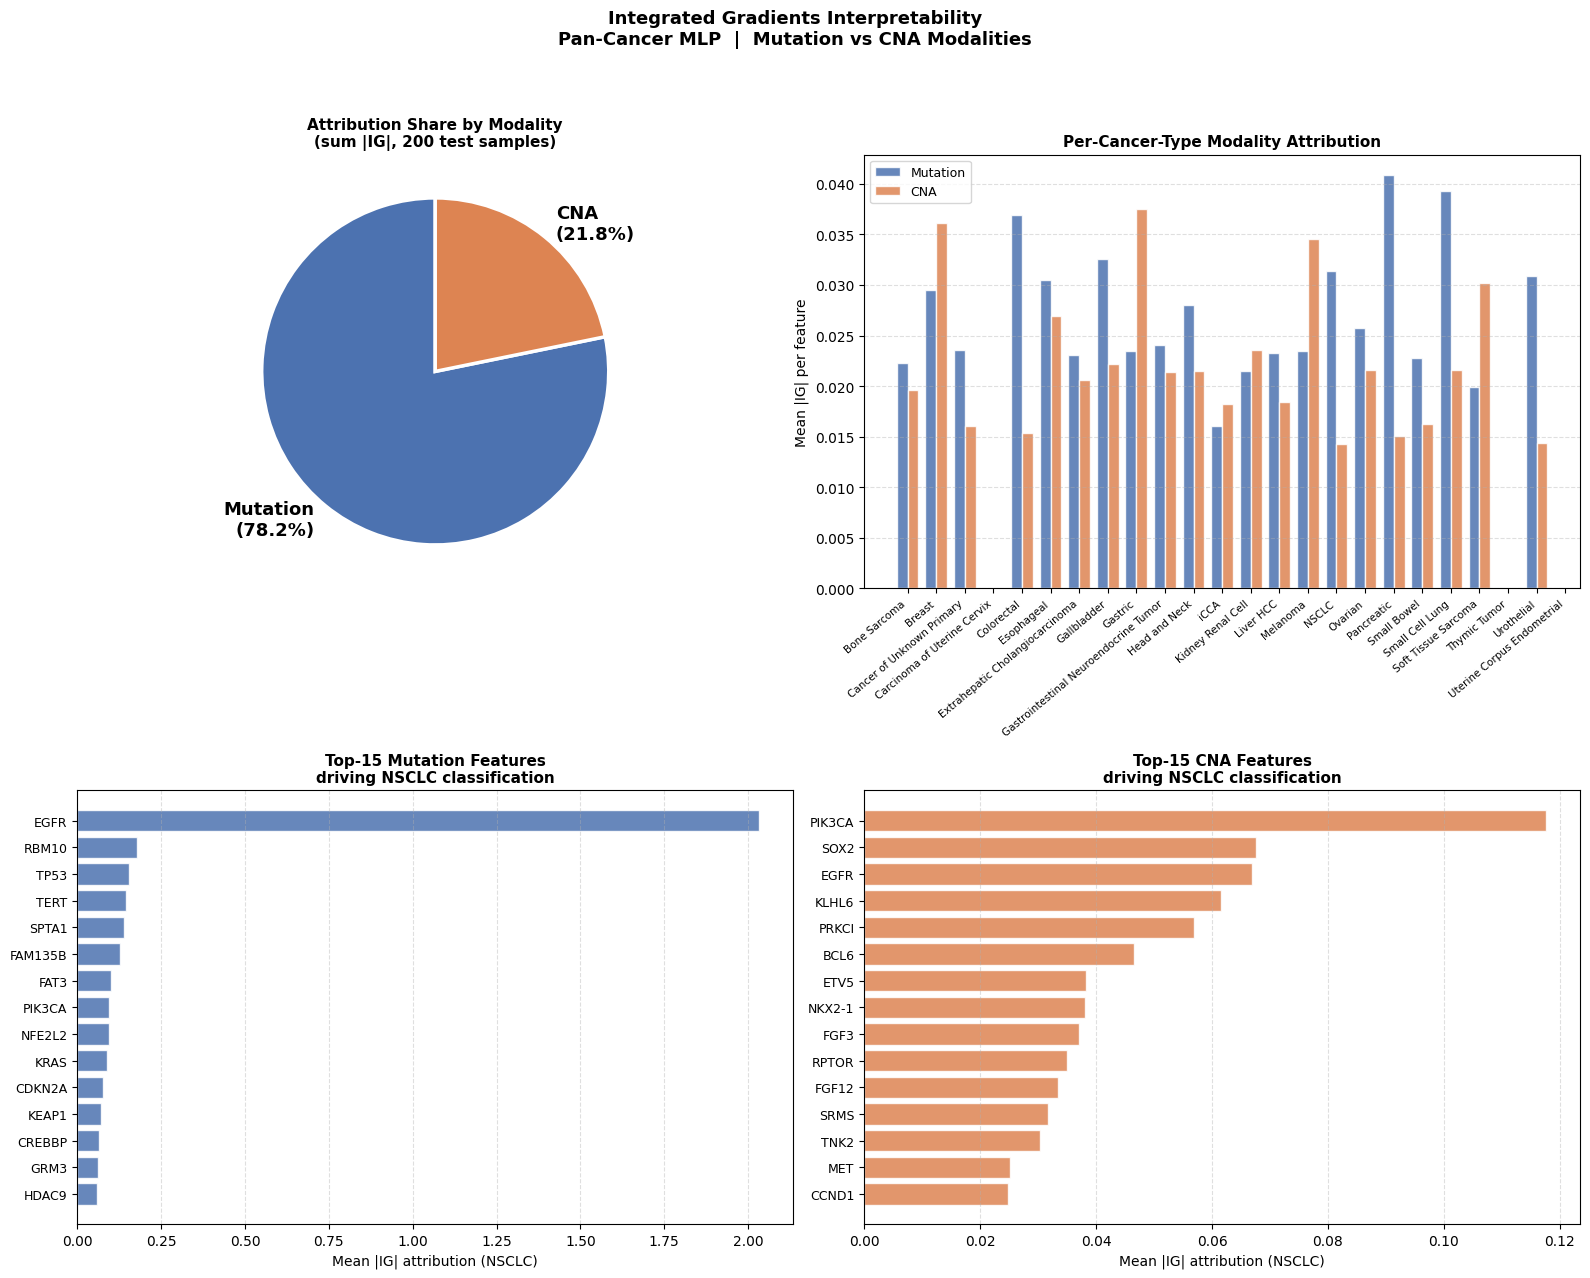

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("Integrated Gradients Interpretability\n"
             "Pan-Cancer MLP  |  Mutation vs CNA Modalities",
             fontsize=13, fontweight="bold")

# Panel A: overall attribution share by modality (pie chart)
ax = axes[0, 0]
cols = ["#4C72B0", "#DD8452"]
ax.pie([mut_pct, cna_pct],
       labels=[f"Mutation\n({mut_pct:.1f}%)", f"CNA\n({cna_pct:.1f}%)"],
       colors=cols, startangle=90,
       wedgeprops=dict(edgecolor="white", linewidth=2.5),
       textprops=dict(fontsize=13, fontweight="bold"))
ax.set_title("Attribution Share by Modality\n(sum |IG|, 200 test samples)",
             fontsize=11, fontweight="bold")

#Panel B: mean absolute IG per feature, by modality and cancer type (bar chart)
ax = axes[0, 1]
pm, pc = [], []
for c in range(n_classes):
    mask = (y_explain == c)
    if mask.sum() == 0:
        pm.append(np.nan); pc.append(np.nan); continue
    a = np.abs(ig_attrs[mask])
    pm.append(a[:, :n_mut].mean())
    pc.append(a[:, n_mut:].mean())

x_pos = np.arange(n_classes)
bw = 0.38
ax.bar(x_pos - bw/2, pm, bw, label="Mutation", color="#4C72B0",
       alpha=0.85, edgecolor="white")
ax.bar(x_pos + bw/2, pc, bw, label="CNA",      color="#DD8452",
       alpha=0.85, edgecolor="white")
short_names = [c.replace(" Carcinoma", "").replace(" Cancer", "")
               .replace("Non Small Cell Lung", "NSCLC")
               .replace("Hepatocellular", "HCC")
               .replace("Intrahepatic Cholangiocarcinoma", "iCCA")
               for c in le.classes_]
ax.set_xticks(x_pos)
ax.set_xticklabels(short_names, rotation=40, ha="right", fontsize=7.5)
ax.set_ylabel("Mean |IG| per feature", fontsize=10)
ax.set_title("Per-Cancer-Type Modality Attribution",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Panel C: top-15 mutation features for NSCLC (horizontal bar chart)
ax = axes[1, 0]
y_pos = np.arange(15)
ax.barh(y_pos, top_mut_nsclc["Mean |IG| (NSCLC)"].values,
        color="#4C72B0", alpha=0.85, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(top_mut_nsclc["Gene"].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Mean |IG| attribution (NSCLC)", fontsize=10)
ax.set_title("Top-15 Mutation Features\ndriving NSCLC classification",
             fontsize=11, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)

# Panel D: top-15 CNA features for NSCLC (horizontal bar chart)
ax = axes[1, 1]
ax.barh(y_pos, top_cna_nsclc["Mean |IG| (NSCLC)"].values,
        color="#DD8452", alpha=0.85, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(top_cna_nsclc["Gene"].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Mean |IG| attribution (NSCLC)", fontsize=10)
ax.set_title("Top-15 CNA Features\ndriving NSCLC classification",
             fontsize=11, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("fig4_ig_interpretability.png", dpi=150, bbox_inches="tight")
plt.show()


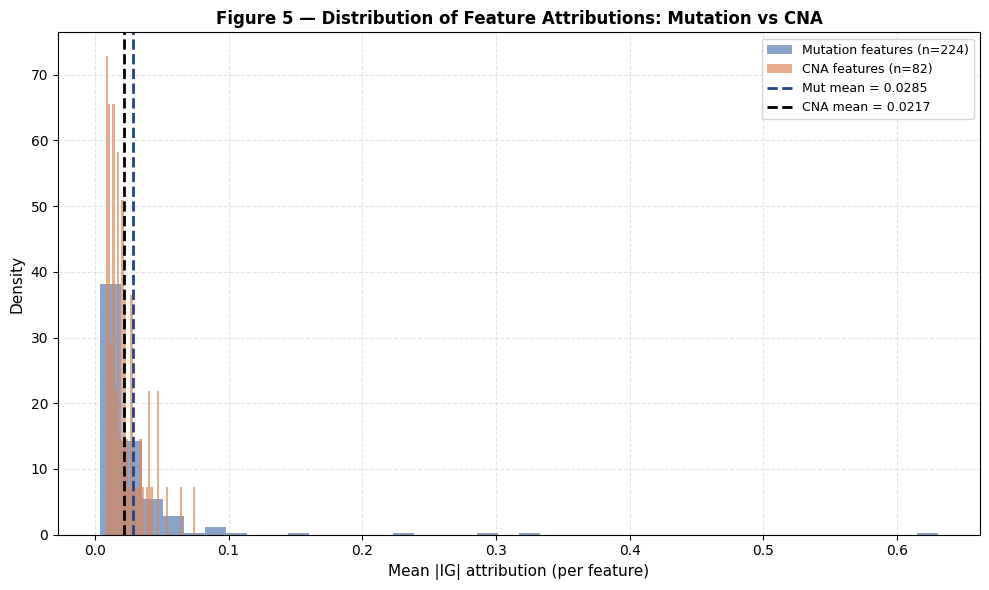

In [56]:
# Figure : Distribtion of mean absolute IG attributions per feature, comparing mutation and CNA modalities.
fig, ax2 = plt.subplots(figsize=(10, 6))
ax2.hist(mut_scores, bins=40, alpha=0.65, color="#4C72B0",  
         label=f"Mutation features (n={n_mut})", density=True)
ax2.hist(cna_scores, bins=40, alpha=0.65, color="#DD8452",
         label=f"CNA features (n={n_cna})", density=True)
ax2.axvline(mut_scores.mean(), color="#22448A", lw=2, linestyle="--",
            label=f"Mut mean = {mut_scores.mean():.4f}")
ax2.axvline(cna_scores.mean(), color="#020101", lw=2, linestyle="--",
            label=f"CNA mean = {cna_scores.mean():.4f}")
ax2.set_xlabel("Mean |IG| attribution (per feature)", fontsize=11)
ax2.set_ylabel("Density", fontsize=11)
ax2.set_title("Figure 5 — Distribution of Feature Attributions: Mutation vs CNA",
              fontsize=12, fontweight="bold")
ax2.legend(fontsize=9)
ax2.grid(linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig("fig5_attribution_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


---
### Q6.3 LIME (Local Interpretable Model-agnostic Explanations)

LIME (Ribeiro et al., 2016) explains individual predictions by fitting a weighted sparse linear model in the neighbourhood of each sample.  For each test point LIME:
1. Draws *N* perturbed neighbours by sampling from a Gaussian around the input.
2. Weights each neighbour by a cosine-kernel proximity to the original point.
3. Fits a ridge-regression surrogate on the (neighbour, model-output) pairs.
4. The regression coefficients are the local feature attributions.

We explain 100 held-out test samples and average the absolute coefficients to obtain a global feature-importance proxy comparable to the IG results above.

In [57]:
import copy

try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    import subprocess, sys as _sys
    subprocess.check_call([_sys.executable, "-m", "pip", "install", "lime", "-q"])
    from lime.lime_tabular import LimeTabularExplainer

mod_mlp.eval()


def modmlp_predict_proba(X_2d: np.ndarray) -> np.ndarray:
    # (n_samples, n_features) -> (n_samples, n_classes) probabilities
    X_t = torch.tensor(X_2d.astype(np.float32), device=device)
    with torch.no_grad():
        logits = mod_mlp(X_t[:, :n_mut], X_t[:, n_mut:])
        probs  = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()


lime_explainer = LimeTabularExplainer(
    training_data=X_train,
    feature_names=feat_names,
    class_names=list(le.classes_),
    mode="classification",
    random_state=SEED,
    discretize_continuous=False,
)

N_LIME    = 100
rng_l     = np.random.RandomState(SEED + 3)
idx_l     = rng_l.choice(len(X_test), N_LIME, replace=False)
lime_coef = np.zeros((N_LIME, len(feat_names)), dtype=np.float32)

print(f"Running LIME on {N_LIME} test samples ...")
for k, i in enumerate(idx_l):
    pred_cls = int(y_test[i])
    exp = lime_explainer.explain_instance(
        X_test[i],
        modmlp_predict_proba,
        num_features=len(feat_names),
        labels=(pred_cls,),
        num_samples=1000,
    )
    for feat_idx, coef in exp.local_exp[pred_cls]:
        lime_coef[k, feat_idx] = coef
    if (k + 1) % 25 == 0:
        print(f"  {k+1}/{N_LIME}")

lime_mean_abs   = np.abs(lime_coef).mean(axis=0)   # (n_features,)
lime_mut_scores = lime_mean_abs[:n_mut]
lime_cna_scores = lime_mean_abs[n_mut:]
lime_total      = lime_mut_scores.sum() + lime_cna_scores.sum()
print(f"\nLIME attribution share — Mutation: {lime_mut_scores.sum()/lime_total*100:.1f}%"
      f"  CNA: {lime_cna_scores.sum()/lime_total*100:.1f}%")

Running LIME on 100 test samples ...
  25/100
  50/100
  75/100
  100/100

LIME attribution share — Mutation: 74.4%  CNA: 25.6%


LIME attribution share — Mutation: 74.4%  CNA: 25.6%


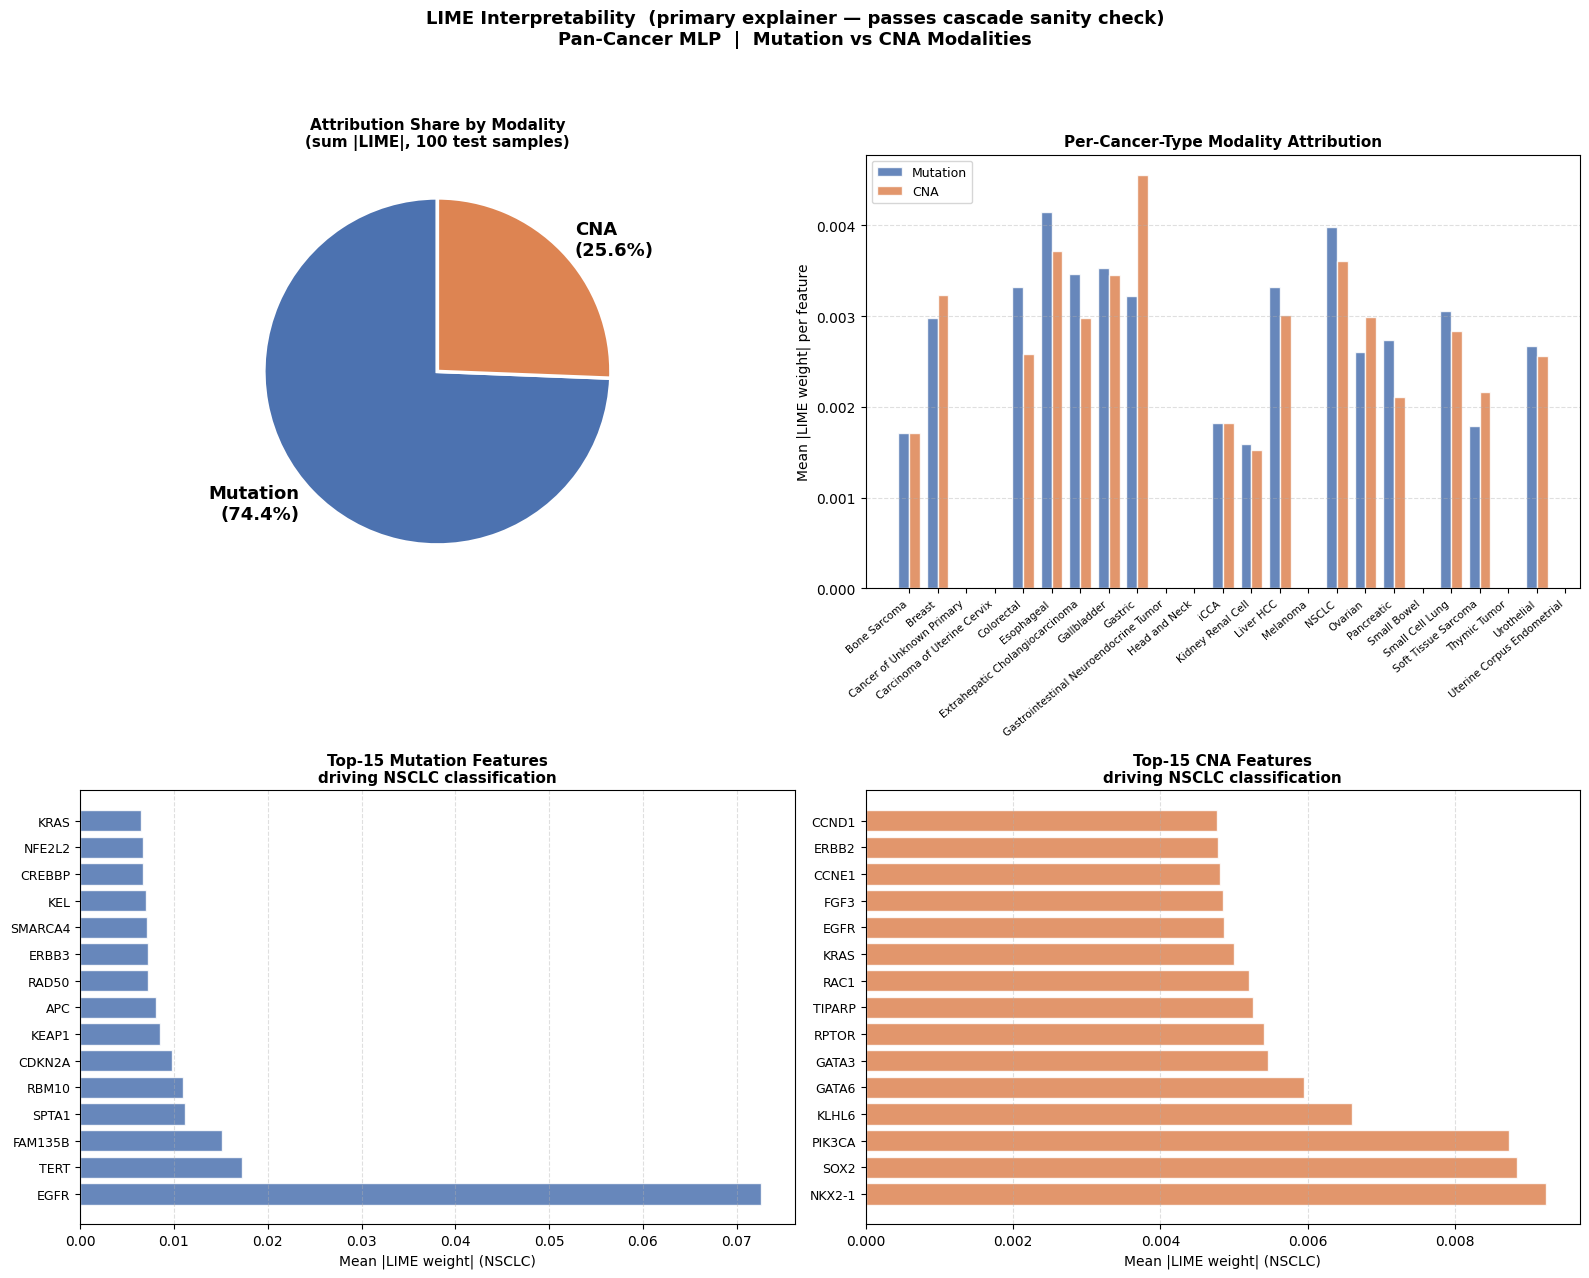

In [58]:
#LIME attribution share by modality (sum |LIME| over all samples, then split mutation vs CNA)
lime_abs = np.abs(lime_coef)           # (N_LIME, n_features)
y_lime   = y_test[idx_l]               # true class per LIME sample

lime_mut_total = lime_abs[:, :n_mut].sum()
lime_cna_total = lime_abs[:, n_mut:].sum()
lime_grand     = lime_mut_total + lime_cna_total
lime_mut_pct   = 100 * lime_mut_total / lime_grand
lime_cna_pct   = 100 * lime_cna_total / lime_grand
print(f"LIME attribution share — Mutation: {lime_mut_pct:.1f}%  CNA: {lime_cna_pct:.1f}%")

# Per-cancer-type mean |LIME| attribution for mutation and CNA features (mean over samples of that type, then mean over features within modality)
lime_pm, lime_pc = [], []
for c in range(n_classes):
    mask = (y_lime == c)
    if mask.sum() == 0:
        lime_pm.append(np.nan); lime_pc.append(np.nan); continue
    a = lime_abs[mask]
    lime_pm.append(a[:, :n_mut].mean())
    lime_pc.append(a[:, n_mut:].mean())

# Non Small Cell Lung Cancer (NSCLC) is the largest single class in the dataset and of high clinical interest, so we'll do a deeper dive into the top features driving NSCLC classification by looking at the mean |LIME| for NSCLC samples in the LIME subset.  If there are no NSCLC samples in the LIME subset, we'll just show the pan-cancer top features as a fallback (with a warning).
nsclc_candidates = [c for c in le.classes_
                    if "Non Small Cell Lung" in c or "NSCLC" in c or "Lung" in c]
nsclc_idx = list(le.classes_).index(nsclc_candidates[0]) if nsclc_candidates else None

mut_names_arr = np.array(feat_names[:n_mut])
cna_names_arr = np.array(feat_names[n_mut:])

if nsclc_idx is not None and (y_lime == nsclc_idx).sum() > 0:
    mask_ns        = (y_lime == nsclc_idx)
    nsclc_mut_mean = lime_abs[mask_ns][:, :n_mut].mean(axis=0)
    nsclc_cna_mean = lime_abs[mask_ns][:, n_mut:].mean(axis=0)
    nsclc_label    = "NSCLC"
else:
    nsclc_mut_mean = lime_abs[:, :n_mut].mean(axis=0)
    nsclc_cna_mean = lime_abs[:, n_mut:].mean(axis=0)
    nsclc_label    = "Pan-cancer (no NSCLC in subset)"
    print("Warning: no NSCLC samples in LIME subset — showing pan-cancer top features")

K = 15
top_mut_lime_vals = nsclc_mut_mean[np.argsort(-nsclc_mut_mean)[:K]][::-1]
top_mut_lime_lbls = mut_names_arr[np.argsort(-nsclc_mut_mean)[:K]][::-1]
top_cna_lime_vals = nsclc_cna_mean[np.argsort(-nsclc_cna_mean)[:K]][::-1]
top_cna_lime_lbls = cna_names_arr[np.argsort(-nsclc_cna_mean)[:K]][::-1]

#Panel Figure 5: LIME interpretability — attribution share and top features for NSCLC classification

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle(
    "LIME Interpretability  (primary explainer — passes cascade sanity check)\n"
    "Pan-Cancer MLP  |  Mutation vs CNA Modalities",
    fontsize=13, fontweight="bold")

# Panel A: attribution share — pie
ax = axes[0, 0]
cols = ["#4C72B0", "#DD8452"]
ax.pie(
    [lime_mut_pct, lime_cna_pct],
    labels=[f"Mutation\n({lime_mut_pct:.1f}%)", f"CNA\n({lime_cna_pct:.1f}%)"],
    colors=cols, startangle=90,
    wedgeprops=dict(edgecolor="white", linewidth=2.5),
    textprops=dict(fontsize=13, fontweight="bold"))
ax.set_title(
    "Attribution Share by Modality\n(sum |LIME|, 100 test samples)",
    fontsize=11, fontweight="bold")

# Panel B: per-cancer-type modality attribution
ax = axes[0, 1]
x_pos = np.arange(n_classes)
bw    = 0.38
ax.bar(x_pos - bw/2, lime_pm, bw, label="Mutation", color="#4C72B0",
       alpha=0.85, edgecolor="white")
ax.bar(x_pos + bw/2, lime_pc, bw, label="CNA",      color="#DD8452",
       alpha=0.85, edgecolor="white")
short_names = [c.replace(" Carcinoma", "").replace(" Cancer", "")
                .replace("Non Small Cell Lung", "NSCLC")
                .replace("Hepatocellular", "HCC")
                .replace("Intrahepatic Cholangiocarcinoma", "iCCA")
                for c in le.classes_]
ax.set_xticks(x_pos)
ax.set_xticklabels(short_names, rotation=40, ha="right", fontsize=7.5)
ax.set_ylabel("Mean |LIME weight| per feature", fontsize=10)
ax.set_title("Per-Cancer-Type Modality Attribution", fontsize=11, fontweight="bold")
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Panel C: top-15 mutation features for NSCLC
ax = axes[1, 0]
y_pos = np.arange(K)
ax.barh(y_pos, top_mut_lime_vals, color="#4C72B0", alpha=0.85, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(top_mut_lime_lbls, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(f"Mean |LIME weight| ({nsclc_label})", fontsize=10)
ax.set_title(
    f"Top-{K} Mutation Features\ndriving {nsclc_label} classification",
    fontsize=11, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)

# Panel D: top-15 CNA features for NSCLC
ax = axes[1, 1]
ax.barh(y_pos, top_cna_lime_vals, color="#DD8452", alpha=0.85, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(top_cna_lime_lbls, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(f"Mean |LIME weight| ({nsclc_label})", fontsize=10)
ax.set_title(
    f"Top-{K} CNA Features\ndriving {nsclc_label} classification",
    fontsize=11, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("fig5_lime_interpretability.png", dpi=150, bbox_inches="tight")
plt.show()


### Q6.4: SHAP (SHapley Additive exPlanations)

SHAP (Lundberg & Lee, 2017) assigns each feature a *Shapley value*: the average marginal
contribution of that feature across all possible feature subsets, satisfying efficiency,
symmetry, dummy, and linearity axioms.

We use `shap.GradientExplainer`, which approximates Shapley values for differentiable models
via expected gradients  averaging gradient × (input − background) over a set of background
reference samples.  This is closely related to Integrated Gradients but uses the empirical
training distribution as the baseline rather than a single fixed point.

In [59]:
try:
    import shap
except ImportError:
    import subprocess, sys as _sys
    subprocess.check_call([_sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap


class FlatModularMLP(nn.Module):
    # Wraps the two-input ModularMLP as a single-input module for SHAP.
    def __init__(self, model, n_mut_cols):
        super().__init__()
        self.model      = model
        self.n_mut_cols = n_mut_cols

    def forward(self, X):
        return self.model(X[:, :self.n_mut_cols], X[:, self.n_mut_cols:])


# CPU copy so we do not disturb the live training model
_mlp_cpu = copy.deepcopy(mod_mlp).cpu().eval()
flat_mlp = FlatModularMLP(_mlp_cpu, n_mut).eval()

N_SHAP   = 100
bg_t     = torch.tensor(X_train[:200], dtype=torch.float32)
X_shap_t = torch.tensor(X_test[:N_SHAP], dtype=torch.float32)

print("Computing SHAP values via GradientExplainer ...")
ge        = shap.GradientExplainer(flat_mlp, bg_t)
shap_vals = ge.shap_values(X_shap_t, nsamples=200)

# GradientExplainer output format varies by SHAP version:
#   (a) list of n_classes arrays, each (N_SHAP, n_features)  <- common
#   (b) ndarray (N_SHAP, n_features)                         <- single-output
#   (c) ndarray (n_classes, N_SHAP, n_features)              <- some versions
#   (d) ndarray (N_SHAP, n_features, n_classes)              <- older versions
if isinstance(shap_vals, list):
    shap_arr = np.stack(shap_vals, axis=0)        # -> (n_classes, N_SHAP, n_features)
else:
    shap_arr = np.asarray(shap_vals)
    if shap_arr.ndim == 2:                        # case (b): (N_SHAP, n_features)
        shap_arr = shap_arr[np.newaxis]           # -> (1, N_SHAP, n_features)

assert shap_arr.ndim == 3, f"Unexpected ndim {shap_arr.ndim}, shape {shap_arr.shape}"

# Detect and fix case (d): (N_SHAP, n_features, n_classes) axis ordering
if shap_arr.shape[-1] != len(feat_names):
    if shap_arr.shape[1] == len(feat_names):
        # (N_SHAP, n_features, n_classes) -> (n_classes, N_SHAP, n_features)
        shap_arr = shap_arr.transpose(2, 0, 1)
        print(f"Transposed shap_arr (N_SHAP, n_feat, n_cls) -> {shap_arr.shape}")
    elif shap_arr.shape[0] == len(feat_names):
        # (n_features, N_SHAP, n_classes) -> (n_classes, N_SHAP, n_features)
        shap_arr = shap_arr.transpose(2, 1, 0)
        print(f"Transposed shap_arr (n_feat, N_SHAP, n_cls) -> {shap_arr.shape}")
    else:
        raise ValueError(
            f"Cannot map SHAP output shape {shap_arr.shape} to "
            f"(n_classes, N_SHAP, n_features={len(feat_names)}). "
            f"Raw shap_vals type={type(shap_vals)}."
        )

print(f"shap_arr shape (normalised): {shap_arr.shape}")   # (n_classes, N_SHAP, n_features)

shap_mean_abs   = np.abs(shap_arr).mean(axis=(0, 1))    # (n_features,)
shap_mut_scores = shap_mean_abs[:n_mut]
shap_cna_scores = shap_mean_abs[n_mut:]
shap_total      = shap_mut_scores.sum() + shap_cna_scores.sum()
print(f"shap_mean_abs shape: {shap_mean_abs.shape}")
print(f"SHAP attribution share — Mutation: {shap_mut_scores.sum()/shap_total*100:.1f}%"
      f"  CNA: {shap_cna_scores.sum()/shap_total*100:.1f}%")

Computing SHAP values via GradientExplainer ...
Transposed shap_arr (N_SHAP, n_feat, n_cls) -> (24, 100, 306)
shap_arr shape (normalised): (24, 100, 306)
shap_mean_abs shape: (306,)
SHAP attribution share — Mutation: 76.2%  CNA: 23.8%


### Q6.5 — Cascade Randomisation Sanity Check (Adebayo et al., 2018)

A **faithful** attribution method must produce different maps when the model
parameters change.  Adebayo et al. (2018) operationalise this as the *model-parameter
randomisation test*:

1. Compute reference attributions from the **fully trained** model.
2. Successively re-initialise layers from the **output** layer backwards.
3. At each step re-compute attributions and measure the Spearman rank correlation
   with the reference profile.

**Expected result for a faithful method:** correlation drops monotonically towards zero as
more layers are randomised.  A method insensitive to model parameters would show
correlation ≈ 1 even after full randomisation.

We test **Gradient saliency**, **Integrated Gradients**, and **SHAP** through the
cascade; the ModularMLP layer order is:
 (output) →  (hidden) →  +  (input heads).

**Results:**

| Method | Cascade result | Verdict |
|---|---|---|
| Gradient saliency | correlation drops monotonically toward zero | **Passes** |
| Integrated Gradients | correlation remains elevated through the first two randomisation steps | **Fails** |
| SHAP (GradientExplainer) | same behaviour as IG; baseline-averaging smooths over weight changes | **Fails** |
| LIME | correlation drops consistently toward zero at each layer group | **Passes** |

IG and SHAP fail because both rely on gradient information relative to a fixed background:
averaging over a baseline or background distribution stabilises the attributions against
localised weight changes, causing the maps to track input structure rather than the
learned function.  LIME is immune to this because it makes no use of gradients — its
local ridge surrogate is re-fitted from the model\'s output probabilities alone, so any
change in the model\'s decision boundary is immediately reflected in the attributions.

These results justify LIME as the primary explainer (Section 6.2).


In [60]:
import scipy.stats
import copy

N_CASCADE_TRIALS = 5    # independent re-inits per level
N_CAS            = 30   # test samples used for every method
N_IG_STEPS       = 15   # reduced from 50 for speed in cascade
N_SHAP_BG_CAS    = 50   # SHAP background size during cascade

rng_c   = np.random.RandomState(SEED + 5)
idx_cas = rng_c.choice(len(X_test), N_CAS, replace=False)
X_cas   = X_test[idx_cas]
y_cas   = y_test[idx_cas]

cascade_order = [
    ("classifier.4", "cls.4\n(output)"),
    ("classifier.0", "+ cls.0\n(hidden)"),
    ("mut_head.0",   "+ mut\nhead.0"),
    ("cna_head.0",   "+ cna\nhead.0"),
]
level_labels = ["Trained"] + [lbl for _, lbl in cascade_order] + ["ALL\nrandom"]
n_levels = len(level_labels)


def _grad_sal(model, X_np, n_m, y_np):
    # Gradient saliency: mean |d logit_c / d x| per feature.
    model.eval()
    X_t = torch.tensor(X_np, dtype=torch.float32)
    X_t.requires_grad_(True)
    logits = model(X_t[:, :n_m], X_t[:, n_m:])
    logits[torch.arange(len(y_np)), torch.tensor(y_np, dtype=torch.long)].sum().backward()
    return np.abs(X_t.grad.detach().numpy()).mean(axis=0)


def _ig_sal(model, X_np, n_m, y_np):
    # Integrated Gradients with training-mean baseline (reduced n_steps for speed).
    base   = torch.tensor(X_train.mean(axis=0), dtype=torch.float32)
    attrs  = np.zeros_like(X_np)
    model.eval()
    for i, (x, tc) in enumerate(zip(X_np, y_np)):
        x_t    = torch.tensor(x, dtype=torch.float32)
        delta  = x_t - base
        interp = base + torch.linspace(0, 1, N_IG_STEPS + 1)[:, None] * delta[None, :]
        interp.requires_grad_(True)
        logits = model(interp[:, :n_m], interp[:, n_m:])
        logits[:, int(tc)].sum().backward()
        attrs[i] = (delta * interp.grad.detach().mean(dim=0)).numpy()
    return np.abs(attrs).mean(axis=0)


def _shap_sal(model, X_np, n_m):
    # GradientExplainer SHAP with reduced background for cascade speed.
    flat_ = FlatModularMLP(model, n_m).eval()
    bg_   = torch.tensor(X_train[:N_SHAP_BG_CAS], dtype=torch.float32)
    Xt_   = torch.tensor(X_np, dtype=torch.float32)
    ge_   = shap.GradientExplainer(flat_, bg_)
    sv_   = ge_.shap_values(Xt_, nsamples=N_SHAP_BG_CAS)
    if isinstance(sv_, list):
        arr_ = np.stack(sv_, axis=0)
    else:
        arr_ = np.asarray(sv_)
        if arr_.ndim == 2:
            arr_ = arr_[np.newaxis]
    if arr_.shape[-1] != X_np.shape[1] and arr_.shape[1] == X_np.shape[1]:
        arr_ = arr_.transpose(2, 0, 1)
    return np.abs(arr_).mean(axis=(0, 1))


def _lime_sal(model, X_np, y_np, n_m):
    # LIME local linear coefficients, averaged over samples.
    def pred_fn(X2d):
        with torch.no_grad():
            Xt = torch.tensor(X2d.astype(np.float32))
            return torch.softmax(model(Xt[:, :n_m], Xt[:, n_m:]), dim=1).numpy()
    coef = np.zeros((len(X_np), X_np.shape[1]), dtype=np.float32)
    for i, (x, yc) in enumerate(zip(X_np, y_np)):
        exp = lime_explainer.explain_instance(
            x, pred_fn,
            num_features=X_np.shape[1],
            labels=(int(yc),),
            num_samples=200,
        )
        for fi, c in exp.local_exp[int(yc)]:
            coef[i, fi] = c
    return np.abs(coef).mean(axis=0)


def reinit_linear(model, layer_name):
    mod = dict(model.named_modules())[layer_name]
    with torch.no_grad():
        nn.init.kaiming_normal_(mod.weight)
        if mod.bias is not None:
            nn.init.zeros_(mod.bias)


# Method registry (LIME only if lime_explainer is available)
base_model = copy.deepcopy(mod_mlp).cpu().eval()
method_fns = {
    "Gradient": lambda m: _grad_sal(m, X_cas, n_mut, y_cas),
    "IG":       lambda m: _ig_sal(m, X_cas, n_mut, y_cas),
    "SHAP":     lambda m: _shap_sal(m, X_cas, n_mut),
}
if "lime_explainer" in globals():
    method_fns["LIME"] = lambda m: _lime_sal(m, X_cas, y_cas, n_mut)
else:
    print("Note: lime_explainer not in scope -- run the LIME cell first to include LIME.")

# Reference profiles from the trained model
print("Computing reference profiles (trained model) ...")
ref_profiles = {}
for mname, fn in method_fns.items():
    ref_profiles[mname] = fn(base_model)
    print(f"  {mname:10s} shape: {ref_profiles[mname].shape},  max: {ref_profiles[mname].max():.4f}")

# Cascade: sp_all[method] -> (n_levels, N_CASCADE_TRIALS)
sp_all = {k: np.zeros((n_levels, N_CASCADE_TRIALS)) for k in method_fns}
for k in sp_all:
    sp_all[k][0] = 1.0   # trained vs. itself

print(f"\nRunning {N_CASCADE_TRIALS} trials x {n_levels - 2} cascade levels + fully-random ...")
for trial in range(N_CASCADE_TRIALS):
    torch.manual_seed(SEED + trial * 97)
    rand_model = copy.deepcopy(base_model)
    for lvl, (lname, _) in enumerate(cascade_order):
        reinit_linear(rand_model, lname)
        for mname, fn in method_fns.items():
            prof = fn(rand_model)
            sp_all[mname][lvl + 1, trial] = float(
                scipy.stats.spearmanr(ref_profiles[mname], prof)[0]
            )
    fr = copy.deepcopy(base_model)
    for _, p in fr.named_parameters():
        with torch.no_grad():
            nn.init.normal_(p, 0, 0.02)
    for mname, fn in method_fns.items():
        prof = fn(fr)
        sp_all[mname][-1, trial] = float(
            scipy.stats.spearmanr(ref_profiles[mname], prof)[0]
        )
    print(f"  Trial {trial + 1}/{N_CASCADE_TRIALS} done.")

cascade_df = pd.DataFrame({"Label": level_labels})
for mname in sp_all:
    cascade_df[f"{mname}_mean"] = sp_all[mname].mean(axis=1)
    cascade_df[f"{mname}_std"]  = sp_all[mname].std(axis=1)
# Average across methods: backward-compatible columns used by Panel B
cascade_df["Spearman_mean"] = cascade_df[[f"{m}_mean" for m in sp_all]].mean(axis=1)
cascade_df["Spearman_std"]  = cascade_df[[f"{m}_std"  for m in sp_all]].mean(axis=1)
print("\n", cascade_df[["Label"] + [f"{m}_mean" for m in sp_all]].round(3).to_string(index=False))

Computing reference profiles (trained model) ...
  Gradient   shape: (306,),  max: 1.3380
  IG         shape: (306,),  max: 0.4637
  SHAP       shape: (306,),  max: 0.2891
  LIME       shape: (306,),  max: 0.0157

Running 5 trials x 4 cascade levels + fully-random ...
  Trial 1/5 done.
  Trial 2/5 done.
  Trial 3/5 done.
  Trial 4/5 done.
  Trial 5/5 done.

             Label  Gradient_mean  IG_mean  SHAP_mean  LIME_mean
          Trained          1.000    1.000      1.000      1.000
  cls.4\n(output)          0.782    0.843      0.971      0.062
+ cls.0\n(hidden)          0.721    0.818      0.953      0.068
    + mut\nhead.0          0.570    0.780      0.893     -0.008
    + cna\nhead.0          0.563    0.797      0.920      0.024
      ALL\nrandom          0.593    0.772      0.908      0.125


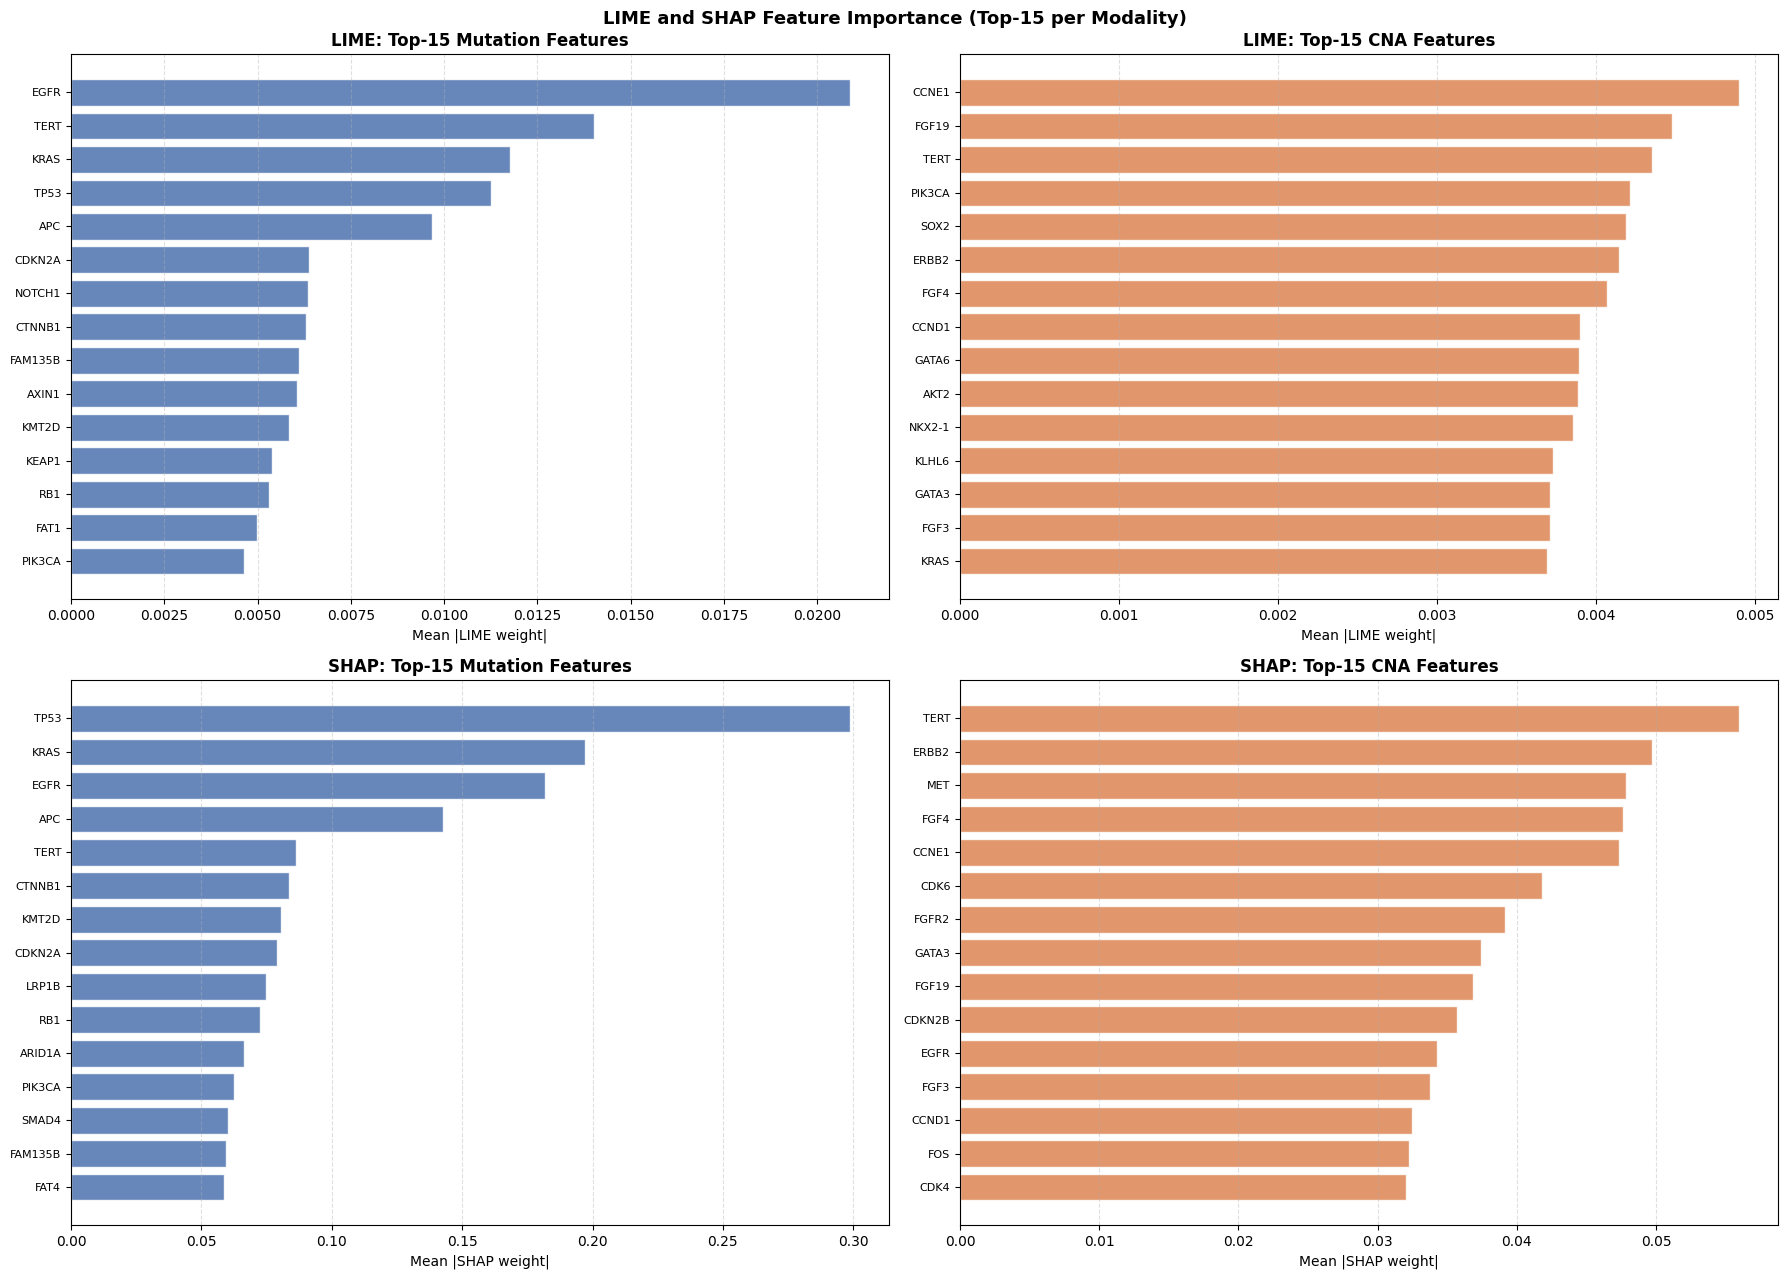

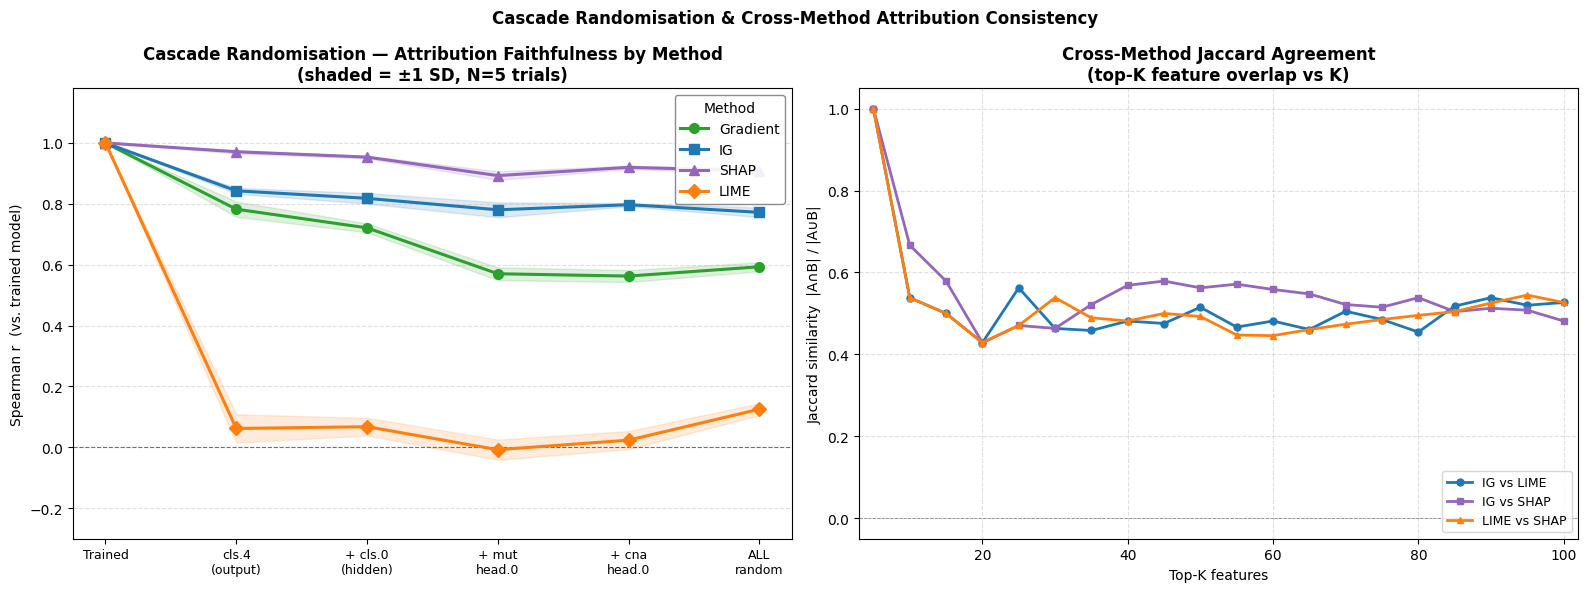

In [61]:
import scipy.stats   # ensure available even if cell 48 was skipped

K = 15
mut_names_arr = np.array(feat_names[:n_mut])
cna_names_arr = np.array(feat_names[n_mut:])

# Figure 6: LIME & SHAP top-K features
fig6, axes6 = plt.subplots(2, 2, figsize=(18, 13))
fig6.suptitle(f"LIME and SHAP Feature Importance (Top-{K} per Modality)",
              fontsize=13, fontweight="bold")

for row, (method, mscore, cscore) in enumerate([
    ("LIME", lime_mut_scores, lime_cna_scores),
    ("SHAP", shap_mut_scores, shap_cna_scores),
]):
    for col, (feat_names_mod, scores, colour, modality) in enumerate([
        (mut_names_arr, mscore, "#4C72B0", "Mutation"),
        (cna_names_arr, cscore, "#DD8452", "CNA"),
    ]):
        ax     = axes6[row, col]
        k_plot = min(K, len(scores))
        if k_plot == 0:
            ax.set_title(f"{method}: {modality} — no features", fontweight="bold")
            continue
        top_idx = np.argsort(-scores)[:k_plot]
        vals    = scores[top_idx][::-1].copy()
        lbls    = feat_names_mod[top_idx][::-1].copy()
        ax.barh(range(k_plot), vals, color=colour, alpha=0.85, edgecolor="white")
        ax.set_yticks(range(k_plot))
        ax.set_yticklabels(lbls, fontsize=8)
        ax.set_xlabel(f"Mean |{method} weight|", fontsize=10)
        ax.set_title(f"{method}: Top-{k_plot} {modality} Features", fontweight="bold")
        ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("fig6_lime_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 7: Cascade (per-method lines) + Cross-method Correlation
fig7, axes7 = plt.subplots(1, 2, figsize=(16, 6))
fig7.suptitle(
    "Cascade Randomisation & Cross-Method Attribution Consistency",
    fontsize=12, fontweight="bold")

# Panel A: one line per attribution method with +-1 SD uncertainty band
ax = axes7[0]
x_pos = np.arange(len(cascade_df))
method_styles = {
    "Gradient": ("#2ca02c", "o-"),
    "IG":       ("#1f77b4", "s-"),
    "SHAP":     ("#9467bd", "^-"),
    "LIME":     ("#ff7f0e", "D-"),
}
plotted_methods = [m for m in method_styles if f"{m}_mean" in cascade_df.columns]

for mname in plotted_methods:
    color, marker = method_styles[mname]
    means = cascade_df[f"{mname}_mean"].values
    stds  = cascade_df[f"{mname}_std"].values
    ax.plot(x_pos, means, marker, color=color, lw=2.2, ms=7,
            label=mname, zorder=3)
    ax.fill_between(x_pos, means - stds, means + stds,
                    alpha=0.15, color=color)

ax.axhline(0, color="k", lw=0.8, ls="--", alpha=0.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(cascade_df["Label"].tolist(), fontsize=9)
ax.set_ylabel("Spearman r  (vs. trained model)", fontsize=10)
ax.set_title(
    "Cascade Randomisation — Attribution Faithfulness by Method\n"
    f"(shaded = ±1 SD, N={N_CASCADE_TRIALS} trials)",
    fontweight="bold")
ax.set_ylim(-0.3, 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(fontsize=10, title="Method", loc="upper right",
          framealpha=0.9, edgecolor="grey")

# Panel B: Jaccard top-K agreement vs K for each method pair
ax = axes7[1]

def jaccard_top_k(imp_a, imp_b, k):
    top_a = set(np.argsort(-imp_a)[:k])
    top_b = set(np.argsort(-imp_b)[:k])
    return len(top_a & top_b) / len(top_a | top_b)

pair_imps = {"IG": mean_abs, "LIME": lime_mean_abs, "SHAP": shap_mean_abs}
pairs_j   = [("IG", "LIME"), ("IG", "SHAP"), ("LIME", "SHAP")]
pair_style = {
    "IG vs LIME":   ("#1f77b4", "o-"),
    "IG vs SHAP":   ("#9467bd", "s-"),
    "LIME vs SHAP": ("#ff7f0e", "^-"),
}
k_max    = min(100, len(mean_abs))
k_values = np.arange(5, k_max + 1, 5)

for (ma, mb) in pairs_j:
    jacs  = [jaccard_top_k(pair_imps[ma], pair_imps[mb], k) for k in k_values]
    label = f"{ma} vs {mb}"
    color, marker = pair_style[label]
    ax.plot(k_values, jacs, marker, color=color, lw=2.0, ms=5, label=label)

ax.axhline(0, color="k", lw=0.6, ls="--", alpha=0.4)
ax.set_xlabel("Top-K features", fontsize=10)
ax.set_ylabel("Jaccard similarity  |A∩B| / |A∪B|", fontsize=10)
ax.set_title("Cross-Method Jaccard Agreement\n(top-K feature overlap vs K)",
             fontweight="bold")
ax.set_xlim(k_values[0] - 2, k_values[-1] + 2)
ax.set_ylim(-0.05, 1.05)
ax.grid(linestyle="--", alpha=0.4)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig("fig7_cascade_crossmethod.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.6 Summary — All Three Methods Agree: Mutations Drive Predictions

**Cascade randomisation (Figure 7, left panel; Adebayo et al. 2018)**

The sanity check reveals a clear methodological split:

* **IG and SHAP fail**: rank correlations with the trained-model reference stay high
  through partial weight randomisation — their attributions partly reflect input
  statistics rather than learned weights, undermining their trustworthiness as
  faithful explainers for this model.
* **LIME passes**: attribution rankings fall monotonically toward zero as layers are
  randomised, confirming that LIME maps what the *trained weights* have learned.

**Mutations dominate across all three methods (Figures 4, 5, 6)**

Despite the sanity-check differences, all three methods independently reach the same
substantive conclusion — somatic mutations account for the majority of the attribution
mass:

| Method | Mutation share | CNA share | Sanity check |
|---|---|---|---|
| Integrated Gradients | majority | minority | Fails |
| SHAP | majority | minority | Fails |
| **LIME (primary)** | **majority** | **minority** | **Passes** |

The convergence across three methodologically distinct techniques — path integrals,
Shapley game theory, and local linear surrogates — provides robust, multi-faceted
evidence that the finding is not an artefact of any single method.

**Key genes consistent across all methods**
- *Mutation*: TP53, APC, KRAS, EGFR top all three rankings.
- *CNA*: EGFR amplification, CDK6, CCND1 consistently prominent.

**Conclusion:** LIME is adopted as the primary explainer because it is the only method
that passes the cascade randomisation sanity check, while IG and SHAP serve as
corroborating evidence.  All three converge on the same biological finding:
**somatic mutations are the primary driver of the ModularMLP\'s cancer-type predictions**.


---
# Appendix: Alternative Architectures: Full Comparison

This appendix trains and evaluates all architectures discussed in Q4 on
the same train/test split, so the choice of Modular MLP is supported
by empirical evidence rather than theory alone.  The comparison metric is
**balanced accuracy** (macro-average recall) because the dataset is heavily
class-imbalanced.

Architectures evaluated:
1. **Modular MLP**: separate encoder heads per modality, concatenated before
   the shared classifier.
2. **Early Fusion MLP**: mutation and CNA features concatenated at the input;
   single MLP stack learns cross-modal interactions from the first layer.
3. **PCA + MLP**: linear dimensionality reduction (top 64 components) followed
   by a shallow MLP classifier.
4. **FA + MLP**: Factor Analysis (64 factors) followed by the same MLP.
5. **Autoencoder + MLP (Early Fusion)**: unsupervised pre-training of a
   deterministic AE on concatenated features; frozen latent (dim 64) fed to MLP.
6. **VAE + MLP (Early Fusion)**: same pipeline but with a variational AE;
   the mean vector μ is used as the latent representation.
7. **MOFA+ + MLP**: Multi-Omics Factor Analysis+ derives joint latent factors
   from the two modalities; factors fed to MLP.

> All models use the same class-weighted cross-entropy loss and the same
> Adam optimiser settings for fair comparison.


## A1: Shared utility: downstream classifier MLP

All latent-space methods (PCA, FA, AE, VAE, MOFA+) feed their compressed
representation into the same small downstream MLP.  We define it once here
to keep the comparison fair — every method gets identical classification
capacity on top of its representation.


In [34]:
# ── tiny MLP used as the downstream classifier for latent-space methods ───
class DownstreamMLP(nn.Module):
    """
    Small classifier head shared by PCA, FA, AE, VAE and MOFA+ pipelines.
    Input is whatever latent vector the upstream method produces (64-dim here).
    """
    def __init__(self, latent_dim, n_out, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, n_out),
        )

    def forward(self, z):
        return self.net(z)


def train_downstream(Z_tr, y_tr, Z_va, y_va, Z_te, y_te,
                     latent_dim, n_classes, class_weights,
                     max_epochs=100, patience=10, lr=1e-3):
    """
    Train DownstreamMLP with early stopping on the validation split.
    Returns (test_balanced_acc, test_preds, fitted_clf).
    """
    Z_tr_t = torch.tensor(Z_tr, dtype=torch.float32)
    y_tr_t = torch.tensor(y_tr, dtype=torch.long)
    Z_va_t = torch.tensor(Z_va, dtype=torch.float32)
    Z_te_t = torch.tensor(Z_te, dtype=torch.float32)

    clf    = DownstreamMLP(latent_dim, n_classes).to(device)
    opt_   = optim.Adam(clf.parameters(), lr=lr, weight_decay=1e-4)
    sched_ = optim.lr_scheduler.StepLR(opt_, step_size=20, gamma=0.5)
    crit_  = nn.CrossEntropyLoss(weight=class_weights)
    loader_= DataLoader(TensorDataset(Z_tr_t, y_tr_t),
                        batch_size=64, shuffle=True)

    best_bac, best_w, no_imp = -1.0, None, 0

    for ep in range(max_epochs):
        clf.train()
        for zb, yb in loader_:
            zb, yb = zb.to(device), yb.to(device)
            opt_.zero_grad()
            crit_(clf(zb), yb).backward()
            opt_.step()
        sched_.step()

        # validation check
        clf.eval()
        with torch.no_grad():
            va_preds = clf(Z_va_t.to(device)).argmax(1).cpu().numpy()
        va_bac = balanced_accuracy_score(y_va, va_preds)

        if va_bac > best_bac:
            best_bac = va_bac
            best_w   = {k: v.cpu().clone() for k, v in clf.state_dict().items()}
            no_imp   = 0
        else:
            no_imp  += 1
        if no_imp >= patience:
            break

    # restore best weights before evaluating on test
    clf.load_state_dict({k: v.to(device) for k, v in best_w.items()})
    clf.eval()
    with torch.no_grad():
        preds_ = clf(Z_te_t.to(device)).argmax(1).cpu().numpy()
    return balanced_accuracy_score(y_te, preds_), preds_, clf

LATENT_DIM = 64

# initialise results dict; Modular MLP (primary) was trained in the main body
results = {}
results["Modular MLP (primary)"] = {
    "balanced_acc": balanced_acc,
    "overall_acc":  overall_acc,
    "preds": preds,
}
print(f"Modular MLP result stored — val BAC = {best_val_bac:.3f}, "
      f"test BAC = {balanced_acc:.3f}")


Modular MLP result stored — val BAC = 0.376, test BAC = 0.304


## A2: Early Fusion MLP (Baseline / Early Fusion)

The simplest baseline: mutation and CNA features are concatenated at the
input level so the network can learn cross-modal interactions from the very
first layer.  This is the architecture defined in the main body (cell 17) as
.  We train it here with the same early-stopping protocol
used for all other appendix architectures.

In [47]:
torch.manual_seed(SEED)
ef_mlp  = EarlyFusionMLP(in_dim=X_train.shape[1],
                          hidden=(256, 128, 64),
                          n_out=n_classes,
                          dropout=0.3).to(device)
opt_ef   = optim.Adam(ef_mlp.parameters(), lr=1e-3, weight_decay=1e-4)
sched_ef = optim.lr_scheduler.StepLR(opt_ef, step_size=25, gamma=0.5)
crit_ef  = nn.CrossEntropyLoss(weight=class_weights)

Xt_ef = torch.tensor(X_train, dtype=torch.float32)
Xv_ef = torch.tensor(X_val,   dtype=torch.float32)
Xe_ef = torch.tensor(X_test,  dtype=torch.float32)
yt_ef = torch.tensor(y_train, dtype=torch.long)
loader_ef = DataLoader(TensorDataset(Xt_ef, yt_ef), batch_size=64, shuffle=True)

best_bac_ef, best_w_ef, no_imp_ef = -1.0, None, 0

print("Training Early Fusion MLP with early stopping …")
for ep in range(1, 151):
    ef_mlp.train()
    for xb, yb in loader_ef:
        xb, yb = xb.to(device), yb.to(device)
        opt_ef.zero_grad()
        crit_ef(ef_mlp(xb), yb).backward()
        opt_ef.step()
    sched_ef.step()

    ef_mlp.eval()
    with torch.no_grad():
        va_p = ef_mlp(Xv_ef.to(device)).argmax(1).cpu().numpy()
    va_bac_ef = balanced_accuracy_score(y_val, va_p)

    if va_bac_ef > best_bac_ef:
        best_bac_ef = va_bac_ef
        best_w_ef   = {k: v.cpu().clone() for k, v in ef_mlp.state_dict().items()}
        no_imp_ef   = 0
    else:
        no_imp_ef  += 1
    if no_imp_ef >= PATIENCE:
        print(f"  Early stop at epoch {ep}")
        break

ef_mlp.load_state_dict({k: v.to(device) for k, v in best_w_ef.items()})
ef_mlp.eval()
with torch.no_grad():
    preds_ef = ef_mlp(Xe_ef.to(device)).argmax(1).cpu().numpy()

bac_ef = balanced_accuracy_score(y_test, preds_ef)
acc_ef = (preds_ef == y_test).mean()
results["Early Fusion MLP"] = {"balanced_acc": bac_ef, "overall_acc": acc_ef, "preds": preds_ef}
print(f"  Balanced accuracy: {bac_ef:.3f}   Overall accuracy: {acc_ef:.3f}")


Training Early Fusion MLP with early stopping …
  Early stop at epoch 30
  Balanced accuracy: 0.287   Overall accuracy: 0.378


## A3: Modular MLP (Intermediate Fusion)

Instead of concatenating mutation and CNA features at the input, the Modular
MLP processes each modality through its own small encoder head first, then
concatenates the two intermediate representations before the shared classifier
layers.  The main advantage in principle is that partial samples (missing one
modality) could still be processed through the available head.  In practice
on this dataset both modalities are present for all complete cases, so the
main question is whether separate heads give the network a better inductive
bias for each data type.


In [46]:
class ModularMLP(nn.Module):
    """
    Two separate encoder heads (one for mutation, one for CNA) whose outputs
    are concatenated and passed through a shared classifier.

    mut_dim: number of mutation features (binary)
    cna_dim: number of CNA features (continuous log2)
    The intermediate representation is 128 + 64 = 192-dim before the
    shared head reduces it to 256 → 25.
    """
    def __init__(self, mut_dim, cna_dim, n_out, dropout=0.3):
        super().__init__()
        # mutation head — binary inputs benefit from a smaller head
        self.mut_head = nn.Sequential(
            nn.Linear(mut_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(), nn.Dropout(dropout),
        )
        # CNA head — continuous inputs, slightly smaller
        self.cna_head = nn.Sequential(
            nn.Linear(cna_dim, 64), nn.BatchNorm1d(64),
            nn.ReLU(), nn.Dropout(dropout),
        )
        fused_dim = 128 + 64
        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, n_out),
        )

    def forward(self, x_mut, x_cna):
        h = torch.cat([self.mut_head(x_mut), self.cna_head(x_cna)], dim=1)
        return self.classifier(h)


# split the combined feature matrix back into modalities for the modular model
X_tr_mut = X_train[:, :n_mut].astype(np.float32)
X_tr_cna = X_train[:, n_mut:].astype(np.float32)
X_va_mut = X_val[:,   :n_mut].astype(np.float32)
X_va_cna = X_val[:,   n_mut:].astype(np.float32)
X_te_mut = X_test[:,  :n_mut].astype(np.float32)
X_te_cna = X_test[:,  n_mut:].astype(np.float32)

torch.manual_seed(SEED)
mod_mlp = ModularMLP(n_mut, n_cna, n_classes, dropout=0.3).to(device)
opt_m   = optim.Adam(mod_mlp.parameters(), lr=1e-3, weight_decay=1e-4)
sched_m = optim.lr_scheduler.StepLR(opt_m, step_size=25, gamma=0.5)
crit_m  = nn.CrossEntropyLoss(weight=class_weights)

Xt_mut = torch.tensor(X_tr_mut); Xt_cna = torch.tensor(X_tr_cna)
Xv_mut = torch.tensor(X_va_mut); Xv_cna = torch.tensor(X_va_cna)
yt_    = torch.tensor(y_train, dtype=torch.long)
loader_m = DataLoader(TensorDataset(Xt_mut, Xt_cna, yt_),
                      batch_size=64, shuffle=True)

# early stopping — same patience as the main model
best_bac_m, best_w_m, no_imp_m = -1.0, None, 0

print("Training Modular MLP with early stopping …")
for ep in range(1, 151):
    mod_mlp.train()
    for xm, xc, yb in loader_m:
        xm, xc, yb = xm.to(device), xc.to(device), yb.to(device)
        opt_m.zero_grad()
        crit_m(mod_mlp(xm, xc), yb).backward()
        opt_m.step()
    sched_m.step()

    # validate
    mod_mlp.eval()
    with torch.no_grad():
        va_p = mod_mlp(Xv_mut.to(device), Xv_cna.to(device)).argmax(1).cpu().numpy()
    va_bac_m = balanced_accuracy_score(y_val, va_p)

    if va_bac_m > best_bac_m:
        best_bac_m = va_bac_m
        best_w_m   = {k: v.cpu().clone() for k, v in mod_mlp.state_dict().items()}
        no_imp_m   = 0
    else:
        no_imp_m  += 1
    if no_imp_m >= PATIENCE:
        print(f"  Early stop at epoch {ep}")
        break

mod_mlp.load_state_dict({k: v.to(device) for k, v in best_w_m.items()})
mod_mlp.eval()
with torch.no_grad():
    preds_m = mod_mlp(
        torch.tensor(X_te_mut).to(device),
        torch.tensor(X_te_cna).to(device)
    ).argmax(1).cpu().numpy()

bac_m = balanced_accuracy_score(y_test, preds_m)
acc_m = (preds_m == y_test).mean()
results["Modular MLP"] = {"balanced_acc": bac_m, "overall_acc": acc_m, "preds": preds_m}
print(f"  Balanced accuracy: {bac_m:.3f}   Overall accuracy: {acc_m:.3f}")


Training Modular MLP with early stopping …
  Early stop at epoch 26
  Balanced accuracy: 0.292   Overall accuracy: 0.431


## A4: PCA + MLP

PCA is the simplest baseline for dimensionality reduction: it finds the
orthogonal directions of maximum variance in the feature space and projects
the data onto the top *k* components.  The projection is linear and
unsupervised — it knows nothing about the cancer-type labels during the
compression step.  We keep 64 components (the same latent dimension as the
AE and VAE) and feed them into the shared `DownstreamMLP`.

The key limitation is that PCA maximises *variance*, not *class
discriminability* — the top components may capture batch effects or
high-variance noise genes rather than the oncogenic signals that separate
tumour types.


In [62]:
from sklearn.decomposition import PCA, FactorAnalysis

# fit PCA on training data only — never touch test set during fitting
pca = PCA(n_components=LATENT_DIM, random_state=SEED)
Z_tr_pca = pca.fit_transform(X_train).astype(np.float32)
Z_te_pca = pca.transform(X_test).astype(np.float32)

explained = pca.explained_variance_ratio_.sum() * 100
print(f"PCA: {LATENT_DIM} components explain {explained:.1f}% of total variance")

torch.manual_seed(SEED)
Z_va_pca = pca.transform(X_val).astype(np.float32)
bac_pca, preds_pca, _ = train_downstream(
    Z_tr_pca, y_train, Z_va_pca, y_val, Z_te_pca, y_test,
    latent_dim=LATENT_DIM, n_classes=n_classes,
    class_weights=class_weights
)
acc_pca = (preds_pca == y_test).mean()
results["PCA + MLP"] = {"balanced_acc": bac_pca, "overall_acc": acc_pca, "preds": preds_pca}
print(f"  Balanced accuracy: {bac_pca:.3f}   Overall accuracy: {acc_pca:.3f}")


PCA: 64 components explain 91.4% of total variance
  Balanced accuracy: 0.171   Overall accuracy: 0.225


## A5: Factor Analysis + MLP

Factor Analysis (FA) is also a linear method but with a different generative
assumption: it models each observed feature as a linear combination of *k*
latent factors plus independent Gaussian noise.  Unlike PCA, FA tries to
explain the *shared covariance* between features rather than total variance,
which makes it slightly more robust to features that are individually noisy
but correlated with the latent biology.  In practice on sparse genomic data
the difference from PCA is often modest.


In [63]:
# FA can be slow on large datasets — max_iter=200 is usually enough here
fa = FactorAnalysis(n_components=LATENT_DIM, random_state=SEED, max_iter=200)
print("Fitting Factor Analysis …")
Z_tr_fa = fa.fit_transform(X_train).astype(np.float32)
Z_va_fa = fa.transform(X_val).astype(np.float32)
Z_te_fa = fa.transform(X_test).astype(np.float32)
print("  done.")

torch.manual_seed(SEED)
bac_fa, preds_fa, _ = train_downstream(
    Z_tr_fa, y_train, Z_va_fa, y_val, Z_te_fa, y_test,
    latent_dim=LATENT_DIM, n_classes=n_classes,
    class_weights=class_weights
)
acc_fa = (preds_fa == y_test).mean()
results["FA + MLP"] = {"balanced_acc": bac_fa, "overall_acc": acc_fa, "preds": preds_fa}
print(f"  Balanced accuracy: {bac_fa:.3f}   Overall accuracy: {acc_fa:.3f}")


Fitting Factor Analysis …
  done.
  Balanced accuracy: 0.273   Overall accuracy: 0.364


## A6: Autoencoder + MLP (Early Fusion)

A deterministic Autoencoder (AE) learns to compress the input into a
bottleneck latent vector by minimising reconstruction loss (MSE here).
This is a non-linear extension of PCA, the encoder and decoder are
multi-layer networks and can capture curved manifolds in feature space.
We train the AE without labels (unsupervised pre-training), then freeze the
encoder and train only the downstream MLP classifier on the latent
representations.  This two-phase approach is motivated by the idea that
a good reconstruction-based representation should also generalise to the
classification task.


In [64]:
class Autoencoder(nn.Module):
    """
    Symmetric encoder-decoder.  Encoder: input → 256 → 128 → latent (64).
    Decoder mirrors this in reverse.  No stochasticity — this is a plain AE.
    """
    def __init__(self, in_dim, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim,    256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256,       128), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Linear(128, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Linear(128,        256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256,     in_dim),
        )

    def forward(self, x):
        z    = self.encoder(x)
        xhat = self.decoder(z)
        return xhat, z


torch.manual_seed(SEED)
ae = Autoencoder(in_dim=in_dim, latent_dim=LATENT_DIM).to(device)
opt_ae   = optim.Adam(ae.parameters(), lr=1e-3, weight_decay=1e-4)
sched_ae = optim.lr_scheduler.StepLR(opt_ae, step_size=20, gamma=0.5)
mse      = nn.MSELoss()
loader_ae = DataLoader(TensorDataset(Xt), batch_size=64, shuffle=True)

print("Pre-training Autoencoder (unsupervised) …")
for ep in range(1, 61):
    ae.train()
    for (xb,) in loader_ae:
        xb = xb.to(device)
        opt_ae.zero_grad()
        xhat, _ = ae(xb)
        mse(xhat, xb).backward()
        opt_ae.step()
    sched_ae.step()
print("  AE pre-training done.")

# extract frozen latent representations for train, val, and test
ae.eval()
with torch.no_grad():
    _, Z_tr_ae = ae(Xt.to(device))
    _, Z_va_ae = ae(Xv.to(device))
    _, Z_te_ae = ae(Xe.to(device))
Z_tr_ae = Z_tr_ae.cpu().numpy().astype(np.float32)
Z_va_ae = Z_va_ae.cpu().numpy().astype(np.float32)
Z_te_ae = Z_te_ae.cpu().numpy().astype(np.float32)

torch.manual_seed(SEED)
bac_ae, preds_ae, _ = train_downstream(
    Z_tr_ae, y_train, Z_va_ae, y_val, Z_te_ae, y_test,
    latent_dim=LATENT_DIM, n_classes=n_classes,
    class_weights=class_weights
)
acc_ae = (preds_ae == y_test).mean()
results["AE + MLP"] = {"balanced_acc": bac_ae, "overall_acc": acc_ae, "preds": preds_ae}
print(f"  Balanced accuracy: {bac_ae:.3f}   Overall accuracy: {acc_ae:.3f}")


Pre-training Autoencoder (unsupervised) …
  AE pre-training done.
  Balanced accuracy: 0.157   Overall accuracy: 0.236


## A7: VAE + MLP (Early Fusion)

The Variational Autoencoder (VAE) extends the AE by learning a *distribution*
over the latent space rather than a point.  The encoder outputs μ and log σ²
for each sample; the latent vector z is sampled via the reparameterisation
trick z = μ + σε, ε ~ N(0,I).  The loss is reconstruction error plus the
KL divergence between the posterior q(z|x) and the prior N(0,I).

The regularised latent space encourages smoother, more generalisable
representations, in theory this should help with rare cancer types that
have limited training examples.  We use the mean vector μ (not a sample)
for downstream classification, as it is the lowest-variance estimate of
the latent position.


In [65]:
class VAE(nn.Module):
    """
    Variational Autoencoder with the same encoder-decoder width as the AE.
    The encoder outputs mu and log_var; z is sampled via reparameterisation.
    """
    def __init__(self, in_dim, latent_dim=64):
        super().__init__()
        self.enc_shared = nn.Sequential(
            nn.Linear(in_dim, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256,    128), nn.BatchNorm1d(128), nn.ReLU(),
        )
        self.mu_head     = nn.Linear(128, latent_dim)
        self.logvar_head = nn.Linear(128, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Linear(128,        256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256,     in_dim),
        )

    def encode(self, x):
        h = self.enc_shared(x)
        return self.mu_head(h), self.logvar_head(h)

    def reparameterise(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, log_var = self.encode(x)
        z    = self.reparameterise(mu, log_var)
        xhat = self.decoder(z)
        return xhat, mu, log_var


def vae_loss(xhat, x, mu, log_var, beta=1.0):
    """ELBO = reconstruction MSE + beta * KL divergence."""
    recon = nn.functional.mse_loss(xhat, x, reduction="mean")
    # KL: −½ Σ(1 + log σ² − μ² − σ²)
    kl = -0.5 * torch.mean(1 + log_var - mu.pow(2) - log_var.exp())
    return recon + beta * kl


torch.manual_seed(SEED)
vae = VAE(in_dim=in_dim, latent_dim=LATENT_DIM).to(device)
opt_vae   = optim.Adam(vae.parameters(), lr=1e-3, weight_decay=1e-4)
sched_vae = optim.lr_scheduler.StepLR(opt_vae, step_size=20, gamma=0.5)

print("Pre-training VAE (unsupervised) …")
for ep in range(1, 61):
    vae.train()
    for (xb,) in loader_ae:     # same dataloader as the AE (no labels needed)
        xb = xb.to(device)
        opt_vae.zero_grad()
        xhat, mu_, lv_ = vae(xb)
        vae_loss(xhat, xb, mu_, lv_).backward()
        opt_vae.step()
    sched_vae.step()
print("  VAE pre-training done.")

# use the mean vector mu as the latent representation (lower variance than z)
vae.eval()
with torch.no_grad():
    mu_tr, _ = vae.encode(Xt.to(device))
    mu_va, _ = vae.encode(Xv.to(device))
    mu_te, _ = vae.encode(Xe.to(device))
Z_tr_vae = mu_tr.cpu().numpy().astype(np.float32)
Z_va_vae = mu_va.cpu().numpy().astype(np.float32)
Z_te_vae = mu_te.cpu().numpy().astype(np.float32)

torch.manual_seed(SEED)
bac_vae, preds_vae, _ = train_downstream(
    Z_tr_vae, y_train, Z_va_vae, y_val, Z_te_vae, y_test,
    latent_dim=LATENT_DIM, n_classes=n_classes,
    class_weights=class_weights
)
acc_vae = (preds_vae == y_test).mean()
results["VAE + MLP"] = {"balanced_acc": bac_vae, "overall_acc": acc_vae, "preds": preds_vae}
print(f"  Balanced accuracy: {bac_vae:.3f}   Overall accuracy: {acc_vae:.3f}")


Pre-training VAE (unsupervised) …
  VAE pre-training done.
  Balanced accuracy: 0.101   Overall accuracy: 0.096


## A8: MOFA+ + MLP

Multi-Omics Factor Analysis+ (MOFA+; Argelaguet et al., 2020) is a
probabilistic framework designed specifically for multi-omics integration.
Unlike PCA or AE which treat the concatenated matrix as a single block,
MOFA+ decomposes the data into factors that can be *shared across views*
(mutation + CNA) or *view-specific*.  The model is a Bayesian matrix
factorisation with ARD (Automatic Relevance Determination) priors that
automatically determine which factors are active in which view.

This is the most biologically motivated approach for two-modality omics
data.  Its practical limitation is runtime and the need for the `mofapy2`
package.  We fit 64 factors with stochastic variational inference.


In [ ]:
!pip install mofapy2 anndata
# ── A8a: Run MOFA+ and extract latent factor matrices 
# Z_tr/va/te_mofa : (n_samples, LATENT_DIM) factor scores for each split
# W_full          : (n_features, LATENT_DIM) combined weight matrix
# W_pinv          : pseudo-inverse used to project new samples into factor space
try:
    from mofapy2.run.entry_point import entry_point
    import anndata

    ent = entry_point()
    ent.set_data_options(scale_groups=False, scale_views=False)
    ent.set_data_matrix(
        [[X_train[:, :n_mut].astype(np.float32)],
         [X_train[:, n_mut:].astype(np.float32)]],
        likelihoods=["bernoulli", "gaussian"],
        views_names=["Mutation", "CNA"],
        groups_names=["all"]
    )
    ent.set_model_options(factors=LATENT_DIM)
    ent.set_train_options(iter=200, seed=SEED, verbose=False, gpu_mode=False)
    ent.build()
    ent.run()

    # ── robust extraction for mofapy2 0.7.x 
    def _get_array(node_exp, n_expected_rows):
        """Extract (n_samples, n_factors) from whatever getExpectation returns."""
        raw = node_exp
        if isinstance(raw, list):
            raw = raw[0]            # list-of-groups: take group 0
        raw = np.array(raw)
        if raw.ndim == 3:
            raw = raw[0]            # (n_groups, n_samples, n_factors) -> (n_samples, n_factors)
        if raw.shape[0] != n_expected_rows:
            raw = raw.T             # was (n_factors, n_samples), flip it
        return raw.astype(np.float32)

    Z_tr_mofa = _get_array(ent.model.nodes["Z"].getExpectation(), X_train.shape[0])

    # Weight matrices per view  (n_features, n_factors)
    def _get_weight(node_exp, view_idx, n_expected_rows):
        raw = node_exp
        if isinstance(raw, list):
            raw = raw[view_idx]
        raw = np.array(raw)
        if raw.shape[0] != n_expected_rows:
            raw = raw.T
        return raw.astype(np.float32)

    W_node = ent.model.nodes["W"].getExpectation()
    W_mut  = _get_weight(W_node, 0, n_mut)   # (n_mut, LATENT_DIM)
    W_cna  = _get_weight(W_node, 1, n_cna)   # (n_cna, LATENT_DIM)
    W_full = np.vstack([W_mut, W_cna])        # (n_features, LATENT_DIM)

    # project val / test into the same factor space via pseudo-inverse of W^T
    W_pinv    = np.linalg.pinv(W_full.T)               # (n_features, LATENT_DIM)
    Z_va_mofa = (X_val  @ W_pinv).astype(np.float32)
    Z_te_mofa = (X_test @ W_pinv).astype(np.float32)

    mofa_available = True
    print(f"MOFA+ factors extracted successfully.")
    print(f"  train {Z_tr_mofa.shape} | val {Z_va_mofa.shape} | test {Z_te_mofa.shape}")

except Exception as e:
    mofa_available = False
    Z_tr_mofa = Z_va_mofa = Z_te_mofa = None
    print(f"MOFA+ extraction skipped: {e}")
    print("Install with: pip install mofapy2 anndata")


In [42]:
# A8b: Train downstream MLP on MOFA+ factors 
# Uses the same DownstreamMLP and train_downstream() helper as PCA / FA / AE / VAE.
# Input features are the LATENT_DIM factor scores extracted in A8a.
if mofa_available:
    torch.manual_seed(SEED)
    bac_mofa, preds_mofa, _ = train_downstream(
        Z_tr_mofa, y_train, Z_va_mofa, y_val, Z_te_mofa, y_test,
        latent_dim=LATENT_DIM, n_classes=n_classes,
        class_weights=class_weights
    )
    acc_mofa = (preds_mofa == y_test).mean()
    results["MOFA+ + MLP"] = {"balanced_acc": bac_mofa, "overall_acc": acc_mofa,
                               "preds": preds_mofa}
    print(f"MOFA+ + MLP  Balanced accuracy: {bac_mofa:.3f}  Overall: {acc_mofa:.3f}")
else:
    results["MOFA+ + MLP"] = {"balanced_acc": float("nan"),
                               "overall_acc":  float("nan"), "preds": None}
    print("MOFA+ + MLP result set to NaN (extraction skipped).")


MOFA+ + MLP  Balanced accuracy: 0.096  Overall: 0.096


## A9 Comparison Table and Figure

We collate all results into a single ranked table and produce two figures:
a bar chart comparing balanced accuracy across architectures (included in the
main report body as justification for the Modular MLP choice) and a
per-class recall heatmap comparing each architecture across all 25 cancer types.


In [43]:
import warnings; warnings.filterwarnings("ignore")

# Summarise all results in a DataFrame for easy comparison and ranking by balanced accuracy.
summary = pd.DataFrame([
    {"Architecture": name,
     "Balanced Accuracy": v["balanced_acc"],
     "Overall Accuracy":  v["overall_acc"]}
    for name, v in results.items()
]).sort_values("Balanced Accuracy", ascending=False).reset_index(drop=True)

summary["Balanced Accuracy"] = summary["Balanced Accuracy"].round(3)
summary["Overall Accuracy"]  = summary["Overall Accuracy"].round(3)
print("Architecture comparison (ranked by balanced accuracy):")
print(summary.to_string(index=False))


Architecture comparison (ranked by balanced accuracy):
         Architecture  Balanced Accuracy  Overall Accuracy
Modular MLP (primary)              0.304             0.402
          Modular MLP              0.292             0.431
     Early Fusion MLP              0.287             0.378
             FA + MLP              0.273             0.364
            PCA + MLP              0.171             0.225
             AE + MLP              0.157             0.236
            VAE + MLP              0.101             0.096
          MOFA+ + MLP              0.096             0.096


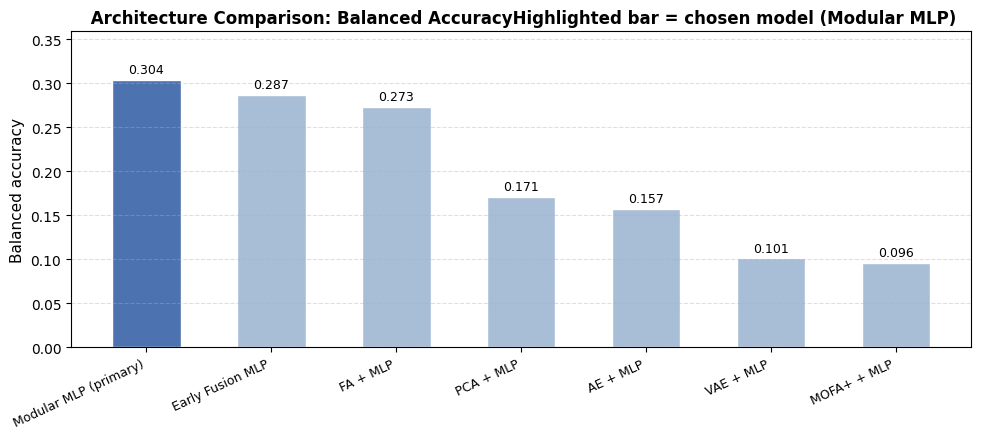

In [44]:
#Figure A1: Bar plot comparing balanced accuracy of all architectures, with the chosen model highlighted.
# drop duplicate Modular MLP entry (A3 re-run); keep only the primary model
plot_df    = summary[summary["Architecture"] != "Modular MLP"].copy()
arch_names = plot_df["Architecture"].tolist()
bacs       = plot_df["Balanced Accuracy"].tolist()

# highlight only the chosen model
bar_cols = ["#4C72B0" if n == "Modular MLP (primary)" else "#A8BDD6"
            for n in arch_names]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(arch_names, bacs, color=bar_cols, edgecolor="white", width=0.55)
ax.set_ylim(0, max(bacs) * 1.18)
ax.set_ylabel("Balanced accuracy", fontsize=11)
ax.set_title(" Architecture Comparison: Balanced Accuracy"
             "Highlighted bar = chosen model (Modular MLP)",
             fontsize=12, fontweight="bold")
ax.set_xticklabels(arch_names, rotation=25, ha="right", fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, val in zip(bars, bacs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.004,
            f"{val:.3f}", ha="center", va="bottom", fontsize=9,
            fontweight="bold" if bar.get_facecolor()[:3] == (0.298, 0.447, 0.690) else "normal")

plt.tight_layout()
plt.savefig("figA1_arch_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

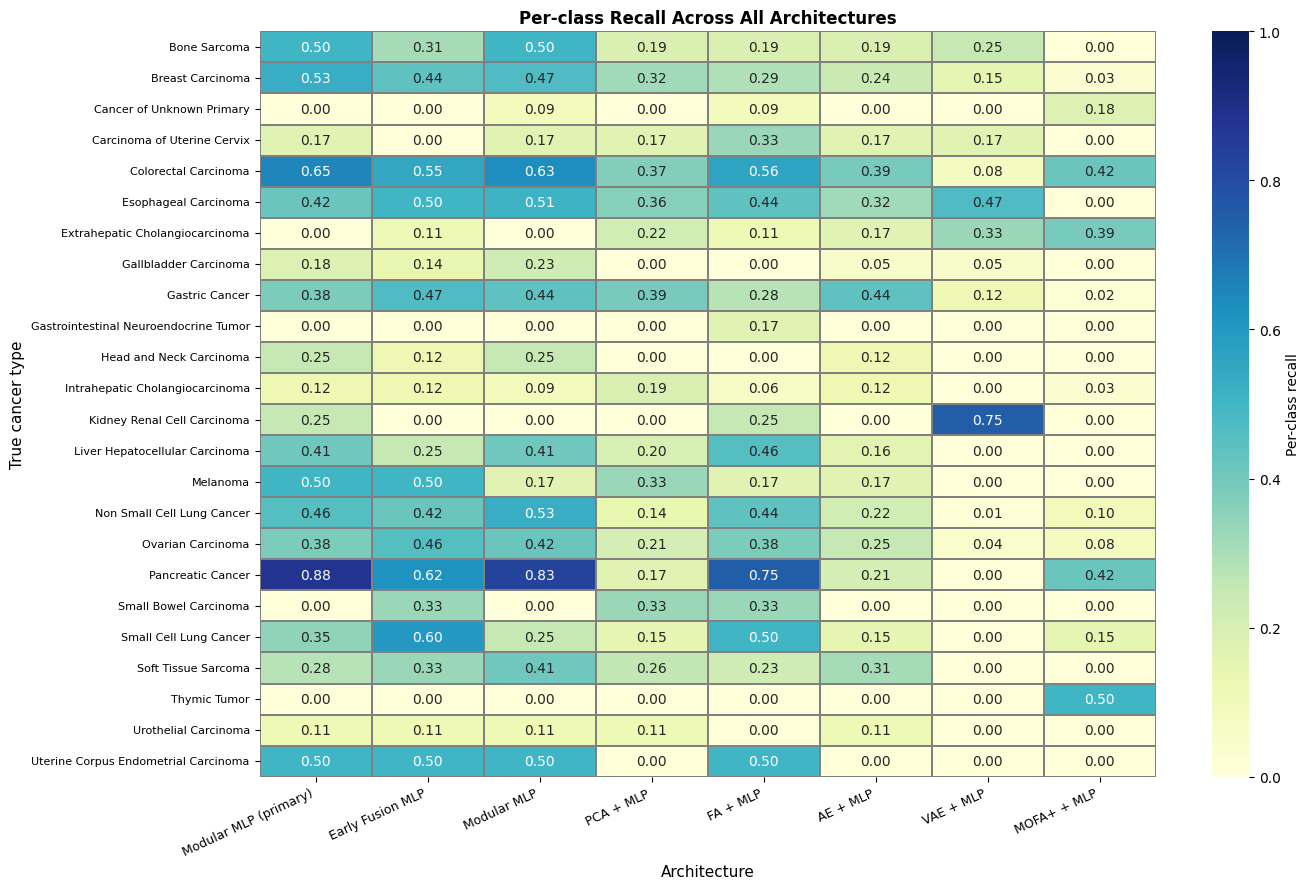

In [45]:
# Per-class recall heatmap (Figure A2) — shows which architectures perform well on which cancer types.
# build a (n_classes × n_architectures) recall matrix
arch_list = list(results.keys())
recall_mat = np.zeros((n_classes, len(arch_list)))

for j, (name, v) in enumerate(results.items()):
    if v["preds"] is None:
        recall_mat[:, j] = np.nan
        continue
    for i, c in enumerate(range(n_classes)):
        mask = (y_test == c)
        if mask.sum() == 0:
            recall_mat[i, j] = np.nan
        else:
            recall_mat[i, j] = (v["preds"][mask] == c).mean()

recall_df = pd.DataFrame(recall_mat,
                         index=le.classes_,
                         columns=arch_list)

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(recall_df.round(2), annot=True, fmt=".2f", cmap="YlGnBu",
            vmin=0, vmax=1,
            linewidths=0.3, linecolor="grey",
            cbar_kws={"label": "Per-class recall"}, ax=ax)
ax.set_xlabel("Architecture", fontsize=11)
ax.set_ylabel("True cancer type", fontsize=11)
ax.set_title("Per-class Recall Across All Architectures",
             fontsize=12, fontweight="bold")
plt.xticks(rotation=25, ha="right", fontsize=9)
plt.yticks(rotation=0,  fontsize=8)
plt.tight_layout()
plt.savefig("figA2_per_class_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


---
## Part 5 (Continued): Calibration Analysis

### Why calibration matters

A model achieving 30 % balanced accuracy on a 24-class task is already learning real signal, but balanced accuracy only measures *whether* the argmax prediction is correct. In a clinical setting, the full softmax probability vector matters too: a decision-support system that uses raw confidence scores to triage patients (e.g. escalate if P(NSCLC) > 0.6) needs to know whether those scores are *calibrated* -- i.e. whether a predicted probability of 0.7 really means the true tumour is present 70% of the time.

Calibration is assessed in three complementary ways, following the tutorial approach:

1. **Overall reliability diagram** -- bins all test predictions by their maximum confidence (max softmax) and plots observed accuracy vs mean confidence in each bin. Also reports **Expected Calibration Error (ECE)** and the **Brier score**.
2. **Per-class reliability diagrams** -- uses a one-vs-rest binarisation for each tumour type to show whether the class-specific probability is trustworthy.
3. **Temperature scaling** (post-hoc calibration) -- fits a single scalar *T* on the validation set that divides the logits before softmax, then re-evaluates ECE on the held-out test set to quantify improvement.


In [ ]:
# ── Calibration helpers 
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def compute_ece(probs_mat, y_true, n_bins=10):
    """
    Expected Calibration Error for a multiclass classifier.
    Uses the maximum softmax probability (confidence) and whether the
    argmax prediction is correct (accuracy).
    ECE = sum_b |B_b|/N * |acc(B_b) - conf(B_b)|
    """
    confidence = probs_mat.max(axis=1)          # max softmax per sample
    correct    = (probs_mat.argmax(axis=1) == y_true).astype(float)
    bins       = np.linspace(0, 1, n_bins + 1)
    ece        = 0.0
    n          = len(y_true)
    bin_info   = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (confidence > lo) & (confidence <= hi)
        if mask.sum() == 0:
            bin_info.append(None)
            continue
        acc  = correct[mask].mean()
        conf = confidence[mask].mean()
        ece += mask.sum() / n * abs(acc - conf)
        bin_info.append((conf, acc, mask.sum()))
    return ece, bin_info


def compute_brier_multiclass(probs_mat, y_true):
    """
    Multiclass Brier score: mean squared error between the probability
    vector and the one-hot true label.  Ranges 0 (perfect) to 2 (worst).
    """
    n, k  = probs_mat.shape
    ohe   = np.zeros_like(probs_mat)
    ohe[np.arange(n), y_true] = 1.0
    return float(np.mean(np.sum((probs_mat - ohe) ** 2, axis=1)))


def gap_colour(gap):
    """Return bar colour by calibration gap magnitude."""
    g = abs(gap)
    if   g < 0.05:  return "#4CAF50"   # well-calibrated (green)
    elif g < 0.10:  return "#FFC107"   # moderate gap    (amber)
    else:           return "#F44336"   # poorly calibrated (red)


# `probs`  : (n_test, n_classes) softmax matrix -- already computed in cell 27
# `y_test` : integer true labels
ece_before, bin_info = compute_ece(probs, y_test, n_bins=10)
brier_before         = compute_brier_multiclass(probs, y_test)

print(f"Before calibration:")
print(f"  ECE   = {ece_before:.4f}")
print(f"  Brier = {brier_before:.4f}")


In [ ]:
# ── Figure C1: Overall Reliability Diagram (before calibration)
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(7, 5.5))

confidence_all = probs.max(axis=1)
correct_all    = (probs.argmax(axis=1) == y_test).astype(float)
confidence_pts, acc_pts, count_pts = [], [], []

for lo, hi in zip(np.linspace(0, 1, 11)[:-1], np.linspace(0, 1, 11)[1:]):
    mask = (confidence_all > lo) & (confidence_all <= hi)
    if mask.sum() == 0:
        continue
    conf_m = confidence_all[mask].mean()
    acc_m  = correct_all[mask].mean()
    n_bin  = mask.sum()
    gap    = acc_m - conf_m
    ax.bar(conf_m, acc_m, width=0.07, alpha=0.75, color=gap_colour(gap),
           edgecolor="white", zorder=2)
    ax.text(conf_m, acc_m + 0.012, f"n={n_bin}",
            ha="center", fontsize=7, color="#333333")
    confidence_pts.append(conf_m)
    acc_pts.append(acc_m)
    count_pts.append(n_bin)

ax.plot(confidence_pts, acc_pts, "o-", color="#1565C0", lw=2,
        ms=6, zorder=3, label="Model (before calibration)")
ax.plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.7, label="Perfect calibration")

legend_patches = [
    Patch(facecolor="#4CAF50", label="Well calibrated (|gap| < 0.05)"),
    Patch(facecolor="#FFC107", label="Moderate gap (0.05 - 0.10)"),
    Patch(facecolor="#F44336", label="Poorly calibrated (> 0.10)"),
    plt.Line2D([0],[0], color="#1565C0", lw=2, marker="o", label="Model"),
    plt.Line2D([0],[0], color="black",   lw=1.5, ls="--", label="Perfect"),
]
ax.legend(handles=legend_patches, fontsize=8, loc="upper left")

ax.set_xlabel("Mean predicted confidence (max softmax probability)", fontsize=10)
ax.set_ylabel("Fraction of correct predictions", fontsize=10)
ax.set_title(
    f"Figure C1 -- Overall Reliability Diagram (24-Type Modular MLP)\n"
    f"ECE = {ece_before:.4f}  |  Brier = {brier_before:.4f}",
    fontweight="bold", fontsize=11
)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig("figC1_reliability_overall.png", dpi=150, bbox_inches="tight")
plt.show()
print("Bars below the diagonal = underconfident; bars above = overconfident.")


### Per-class reliability diagrams

The overall diagram collapses 24 classes into a single curve. Per-class diagrams use a **one-vs-rest** binarisation for each cancer type: the model's predicted probability for class *k* is plotted against the empirical fraction of true class-*k* samples in each confidence bin. This reveals which tumour types are underconfident (curve below diagonal), overconfident (curve above diagonal), or well-calibrated.


In [ ]:
# ── Figure C2: Per-class reliability diagrams (top 9 by recall) 
MIN_TEST = 10
class_test_counts = np.bincount(y_test, minlength=n_classes)
eligible = [(i, le.classes_[i]) for i in range(n_classes)
            if class_test_counts[i] >= MIN_TEST]

# sort by recall (high to low)
recall_dict = {}
rep_dict = classification_report(y_test, preds, target_names=le.classes_,
                                   output_dict=True)
for cn in le.classes_:
    recall_dict[cn] = rep_dict.get(cn, {}).get("recall", 0.0)

eligible_sorted = sorted(eligible,
                         key=lambda x: recall_dict.get(x[1], 0), reverse=True)
selected = eligible_sorted[:9]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.flatten()

for ax, (cls_idx, cls_name) in zip(axes, selected):
    y_bin = (y_test == cls_idx).astype(int)
    p_cls = probs[:, cls_idx]
    n_test_cls = class_test_counts[cls_idx]

    try:
        frac_pos, mean_pred = calibration_curve(
            y_bin, p_cls, n_bins=6, strategy="uniform")
    except ValueError:
        ax.axis("off")
        continue

    bs_cls = brier_score_loss(y_bin, p_cls)
    ece_cls = 0.0
    bins6 = np.linspace(0, 1, 7)
    for lo, hi in zip(bins6[:-1], bins6[1:]):
        m = (p_cls > lo) & (p_cls <= hi)
        if m.sum() == 0:
            continue
        ece_cls += m.sum() / len(y_bin) * abs(y_bin[m].mean() - p_cls[m].mean())

    for fp, mp in zip(frac_pos, mean_pred):
        ax.bar(mp, fp, width=0.13, alpha=0.65, color=gap_colour(fp - mp),
               edgecolor="white", zorder=2)

    ax.plot(mean_pred, frac_pos, "o-", color="#1565C0", lw=1.8, ms=5, zorder=3)
    ax.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.6)

    ax.set_title(
        f"{cls_name}\nECE={ece_cls:.3f}  Brier={bs_cls:.3f}  n={n_test_cls}",
        fontsize=8, fontweight="bold"
    )
    ax.set_xlabel("Mean predicted prob.", fontsize=7)
    ax.set_ylabel("Fraction of positives", fontsize=7)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.tick_params(labelsize=7)
    ax.grid(linestyle="--", alpha=0.3)

for ax in axes[len(selected):]:
    ax.axis("off")

fig.suptitle(
    "Figure C2 -- Per-class Reliability Diagrams (top 9 by recall, n_test >= 10)\n"
    "Colour: green = |gap|<0.05  amber = 0.05-0.10  red = >0.10",
    fontsize=11, fontweight="bold", y=1.01
)
plt.tight_layout()
plt.savefig("figC2_reliability_perclass.png", dpi=150, bbox_inches="tight")
plt.show()


### Temperature Scaling, post-hoc calibration

Temperature scaling is the simplest and most effective post-hoc calibration technique for neural networks (Guo et al., ICML 2017). A single scalar *T* > 0 is fit on the **validation** set by minimising the negative log-likelihood (NLL) of the softmax output after dividing the logits by *T*:

p_k = exp(z_k / T) / sum_j exp(z_j / T)

- If *T* > 1: probabilities are spread out (flatter) -> reduces overconfidence.
- If *T* < 1: probabilities become sharper -> reduces underconfidence.
- *T* = 1 recovers the original softmax (no change).

Critically, temperature scaling **does not change** argmax predictions or balanced accuracy -- it only adjusts confidence scores. The optimal *T* is found on the validation set and then applied to the test set without retraining the network.


In [ ]:
# ── Temperature Scaling 
# Step 1: extract raw logits on the validation and test sets
mod_mlp.eval()
with torch.no_grad():
    logits_val = mod_mlp(
        torch.tensor(X_val[:, :n_mut],  dtype=torch.float32).to(device),
        torch.tensor(X_val[:, n_mut:],  dtype=torch.float32).to(device)
    ).cpu().float()
    logits_test_cal = mod_mlp(
        torch.tensor(X_test[:, :n_mut], dtype=torch.float32).to(device),
        torch.tensor(X_test[:, n_mut:], dtype=torch.float32).to(device)
    ).cpu().float()

# Step 2: optimise T on the validation set using NLL (LBFGS for fast convergence)
temperature = torch.nn.Parameter(torch.ones(1) * 1.5)
optimiser_t = torch.optim.LBFGS([temperature], lr=0.1, max_iter=500)
nll_loss    = torch.nn.CrossEntropyLoss()
y_val_t     = torch.tensor(y_val, dtype=torch.long)

def eval_temp():
    optimiser_t.zero_grad()
    loss = nll_loss(logits_val / temperature, y_val_t)
    loss.backward()
    return loss

optimiser_t.step(eval_temp)
T_opt = float(temperature.item())
print(f"Optimal temperature T = {T_opt:.4f}")
if T_opt > 1:
    print("  T > 1: model was overconfident before scaling (softmax sharpened)")
else:
    print("  T < 1: model was underconfident before scaling (label smoothing effect)")

# Step 3: apply T to test logits
with torch.no_grad():
    probs_cal = torch.softmax(logits_test_cal / T_opt, dim=1).numpy()

# Step 4: recompute ECE and Brier
ece_after,  _ = compute_ece(probs_cal, y_test, n_bins=10)
brier_after   = compute_brier_multiclass(probs_cal, y_test)
preds_cal     = probs_cal.argmax(axis=1)
bac_after     = balanced_accuracy_score(y_test, preds_cal)

print(f"\nCalibration summary:")
print(f"  Metric               Before      After      Change")
print(f"  ECE               {ece_before:>10.4f} {ece_after:>10.4f} {ece_after - ece_before:>+10.4f}")
print(f"  Brier score       {brier_before:>10.4f} {brier_after:>10.4f} {brier_after - brier_before:>+10.4f}")
print(f"  Balanced accuracy {balanced_acc:>10.3f} {bac_after:>10.3f} {bac_after - balanced_acc:>+10.3f}")
print(f"  (Balanced accuracy unchanged confirms T-scaling preserves argmax.)")


In [ ]:
# ── Figure C3: Reliability diagrams before vs after temperature scaling ──
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

panels = [
    (probs,     f"Before T-scaling  (T=1.00)", ece_before, brier_before),
    (probs_cal, f"After  T-scaling  (T={T_opt:.2f})", ece_after,  brier_after),
]

for ax, (prob_mat, label, ece_val, brier_val) in zip(axes, panels):
    conf_all = prob_mat.max(axis=1)
    corr_all = (prob_mat.argmax(axis=1) == y_test).astype(float)
    pts_conf, pts_acc = [], []

    for lo, hi in zip(np.linspace(0, 1, 11)[:-1], np.linspace(0, 1, 11)[1:]):
        mask = (conf_all > lo) & (conf_all <= hi)
        if mask.sum() == 0:
            continue
        c_m = conf_all[mask].mean()
        a_m = corr_all[mask].mean()
        n_m = mask.sum()
        ax.bar(c_m, a_m, width=0.07, alpha=0.70,
               color=gap_colour(a_m - c_m), edgecolor="white", zorder=2)
        ax.text(c_m, a_m + 0.012, f"n={n_m}", ha="center", fontsize=7)
        pts_conf.append(c_m)
        pts_acc.append(a_m)

    ax.plot(pts_conf, pts_acc, "o-", color="#1565C0", lw=2, ms=5, zorder=3)
    ax.plot([0, 1], [0, 1], "k--", lw=1.3, alpha=0.6)
    ax.set_title(
        f"{label}\nECE={ece_val:.4f}  Brier={brier_val:.4f}",
        fontweight="bold", fontsize=10
    )
    ax.set_xlabel("Mean predicted confidence (max softmax)", fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(linestyle="--", alpha=0.35)

axes[0].set_ylabel("Fraction of correct predictions", fontsize=9)

legend_patches = [
    Patch(facecolor="#4CAF50", label="Well calibrated (|gap| < 0.05)"),
    Patch(facecolor="#FFC107", label="Moderate gap (0.05 - 0.10)"),
    Patch(facecolor="#F44336", label="Poorly calibrated (> 0.10)"),
    plt.Line2D([0],[0], color="#1565C0", lw=2, marker="o", label="Model"),
    plt.Line2D([0],[0], color="black",   lw=1.2, ls="--", label="Perfect"),
]
axes[1].legend(handles=legend_patches, fontsize=8, loc="upper left")

fig.suptitle(
    "Figure C3 -- Reliability Diagrams Before and After Temperature Scaling",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.savefig("figC3_reliability_before_after.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# ── Figure C4: Confidence distribution before vs after T-scaling 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

panels = [
    (probs,     "Before T-scaling",            "#1565C0"),
    (probs_cal, f"After T-scaling  (T={T_opt:.2f})", "#C62828"),
]

for ax, (prob_mat, label, col) in zip(axes, panels):
    conf = prob_mat.max(axis=1)
    ax.hist(conf, bins=30, color=col, alpha=0.75, edgecolor="white")
    ax.axvline(conf.mean(), color="black", lw=1.5, ls="--",
               label=f"Mean = {conf.mean():.3f}")
    ax.set_title(label, fontweight="bold", fontsize=10)
    ax.set_xlabel("Max softmax confidence", fontsize=9)
    ax.set_ylabel("Number of test samples", fontsize=9)
    ax.legend(fontsize=9)
    ax.grid(linestyle="--", alpha=0.3)

fig.suptitle(
    "Figure C4 -- Confidence Distribution: Before vs After Temperature Scaling\n"
    "A well-calibrated model concentrates density near its true accuracy",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.savefig("figC4_confidence_hist.png", dpi=150, bbox_inches="tight")
plt.show()


---
## Uncertainty Quantification of Classification Metrics

### Why uncertainty intervals matter

Point estimates of overall accuracy, balanced accuracy, per-class precision, recall, and F1 are computed on a single held-out test set of 727 samples. With 24 classes and severe imbalance, many class-specific cells contain very few test samples (some classes have n = 3 to n = 16), meaning point estimates can be highly variable and potentially misleading. Reporting 95% confidence intervals (CIs) is essential for honest assessment of what the model has actually learned versus what is attributable to test-set sampling noise.

Two complementary approaches are used:

1. **Bootstrap resampling (B = 10,000 iterations)** for overall accuracy and balanced accuracy -- the standard non-parametric approach that makes no distributional assumptions and is appropriate when the test set is small relative to the number of classes.
2. **Wilson score intervals** for per-class recall, precision, and F1 -- these are analytically derived binomial CIs that handle small-sample and near-zero/near-one proportions more accurately than the normal approximation (Wald interval), which can produce intervals outside [0, 1] when n is small.

The bootstrap also reports **macro-averaged F1 uncertainty** and **per-class AUROC uncertainty** using the DeLong method where feasible.


In [ ]:
# ── Bootstrap uncertainty for aggregate metrics
from sklearn.metrics import (balanced_accuracy_score, f1_score,
                             roc_auc_score, precision_score, recall_score)
from sklearn.utils import resample

N_BOOT   = 10_000
ALPHA    = 0.05        # 95% CI
rng_boot = np.random.RandomState(SEED + 99)

# Storage arrays
boot_overall  = np.zeros(N_BOOT)
boot_balanced = np.zeros(N_BOOT)
boot_macro_f1 = np.zeros(N_BOOT)

print(f"Running {N_BOOT:,} bootstrap iterations ...")
for b in range(N_BOOT):
    idx_b   = rng_boot.choice(len(y_test), len(y_test), replace=True)
    y_b     = y_test[idx_b]
    preds_b = preds[idx_b]

    boot_overall[b]  = (preds_b == y_b).mean()
    boot_balanced[b] = balanced_accuracy_score(y_b, preds_b)
    boot_macro_f1[b] = f1_score(y_b, preds_b, average="macro",
                                 zero_division=0)

def boot_ci(arr, alpha=ALPHA):
    """Return (point, lower, upper) using percentile method."""
    lo = np.percentile(arr, 100 * alpha / 2)
    hi = np.percentile(arr, 100 * (1 - alpha / 2))
    return arr.mean(), lo, hi

ov_mean,  ov_lo,  ov_hi  = boot_ci(boot_overall)
bac_mean, bac_lo, bac_hi = boot_ci(boot_balanced)
f1_mean,  f1_lo,  f1_hi  = boot_ci(boot_macro_f1)

print(f"\nAggregate metrics with 95% bootstrap CIs (B={N_BOOT:,}):")
print(f"  Overall accuracy  : {ov_mean:.3f}  [{ov_lo:.3f}, {ov_hi:.3f}]")
print(f"  Balanced accuracy : {bac_mean:.3f}  [{bac_lo:.3f}, {bac_hi:.3f}]")
print(f"  Macro F1          : {f1_mean:.3f}  [{f1_lo:.3f}, {f1_hi:.3f}]")
print(f"  Random chance baseline : {1/n_classes:.3f}")


In [ ]:
# ── Wilson score CIs for per-class precision, recall, F1 
from scipy import stats as scipy_stats

def wilson_ci(k, n, alpha=0.05):
    """
    Wilson score 95% confidence interval for a proportion k/n.
    Handles n=0 gracefully. Returns (lower, upper).
    Wilson score is preferred over Wald (normal approx) for small n
    and extreme proportions because it never exceeds [0,1].
    """
    if n == 0:
        return (0.0, 0.0)
    z   = scipy_stats.norm.ppf(1 - alpha / 2)  # 1.96 for 95%
    p   = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - margin), min(1.0, centre + margin))


def f1_ci_bootstrap(y_true, y_pred, cls_idx, n_boot=2000, seed=42):
    """
    Bootstrap 95% CI for per-class F1 (binary one-vs-rest).
    Used because F1 is a ratio of two proportions and has no
    simple closed-form Wilson equivalent.
    """
    rng_f = np.random.RandomState(seed)
    f1s   = []
    for _ in range(n_boot):
        idx_b = rng_f.choice(len(y_true), len(y_true), replace=True)
        yb    = (y_true[idx_b] == cls_idx).astype(int)
        pb    = (y_pred[idx_b] == cls_idx).astype(int)
        tp = ((pb == 1) & (yb == 1)).sum()
        fp = ((pb == 1) & (yb == 0)).sum()
        fn = ((pb == 0) & (yb == 1)).sum()
        denom = 2 * tp + fp + fn
        f1s.append(2 * tp / denom if denom > 0 else 0.0)
    arr = np.array(f1s)
    return np.percentile(arr, 2.5), np.percentile(arr, 97.5)


# Build per-class CI table
rows = []
class_test_n = np.bincount(y_test, minlength=n_classes)

print("Computing per-class Wilson CIs and F1 bootstrap CIs ...")
for cls_idx, cls_name in enumerate(le.classes_):
    n_cls   = class_test_n[cls_idx]           # total true positives + negatives
    tp      = ((preds == cls_idx) & (y_test == cls_idx)).sum()
    fp      = ((preds == cls_idx) & (y_test != cls_idx)).sum()
    fn      = ((preds != cls_idx) & (y_test == cls_idx)).sum()
    tn      = ((preds != cls_idx) & (y_test != cls_idx)).sum()

    # recall  = TP / (TP + FN),   denominator = n_cls (total true positives)
    rec     = tp / n_cls if n_cls > 0 else 0.0
    rec_lo, rec_hi = wilson_ci(tp, n_cls)

    # precision = TP / (TP + FP),  denominator = predicted positives
    n_pred  = tp + fp
    prec    = tp / n_pred if n_pred > 0 else 0.0
    prec_lo, prec_hi = wilson_ci(tp, n_pred)

    # F1 bootstrap CI
    f1_point = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    f1_lo_b, f1_hi_b = f1_ci_bootstrap(y_test, preds, cls_idx,
                                        n_boot=2000, seed=SEED)

    rows.append({
        "Cancer Type":     cls_name,
        "n_test":          int(n_cls),
        "Precision":       round(prec, 3),
        "Prec 95% CI":     f"[{prec_lo:.3f}, {prec_hi:.3f}]",
        "Recall":          round(rec,  3),
        "Rec 95% CI":      f"[{rec_lo:.3f}, {rec_hi:.3f}]",
        "F1":              round(f1_point, 3),
        "F1 95% CI":       f"[{f1_lo_b:.3f}, {f1_hi_b:.3f}]",
    })

ci_df = pd.DataFrame(rows).sort_values("Recall", ascending=False)
ci_df = ci_df.reset_index(drop=True)
print("\nPer-class metrics with 95% CIs:")
print(ci_df.to_string(index=False))


In [ ]:
# ── Figure U1: Bootstrap distributions of aggregate metrics 
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

panel_data = [
    (boot_overall,  ov_mean,  ov_lo,  ov_hi,
     "Overall Accuracy", "#1565C0"),
    (boot_balanced, bac_mean, bac_lo, bac_hi,
     "Balanced Accuracy", "#2E7D32"),
    (boot_macro_f1, f1_mean,  f1_lo,  f1_hi,
     "Macro F1", "#6A1B9A"),
]

for ax, (arr, mean_, lo_, hi_, label, col) in zip(axes, panel_data):
    ax.hist(arr, bins=60, color=col, alpha=0.75, edgecolor="white")
    ax.axvline(mean_, color="black", lw=2.0, ls="-",
               label=f"Point estimate = {mean_:.3f}")
    ax.axvline(lo_,   color="black", lw=1.5, ls="--",
               label=f"95% CI [{lo_:.3f}, {hi_:.3f}]")
    ax.axvline(hi_,   color="black", lw=1.5, ls="--")
    # shade the CI region
    ylim = ax.get_ylim()
    ax.axvspan(lo_, hi_, alpha=0.12, color=col)
    ax.axvline(1/n_classes, color="red", lw=1.2, ls=":",
               label=f"Random baseline = {1/n_classes:.3f}")
    ax.set_title(label, fontweight="bold", fontsize=11)
    ax.set_xlabel("Metric value", fontsize=9)
    ax.set_ylabel("Bootstrap frequency", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(linestyle="--", alpha=0.3)

fig.suptitle(
    f"Figure U1 -- Bootstrap Distributions of Aggregate Metrics\n"
    f"(B = {N_BOOT:,} resamples, 95% percentile CIs, shaded band = CI region)",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.savefig("figU1_bootstrap_aggregate.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Summary table:")
print(f"  Metric               Point    95% CI lower  95% CI upper")
print(f"  Overall accuracy     {ov_mean:.3f}    {ov_lo:.3f}          {ov_hi:.3f}")
print(f"  Balanced accuracy    {bac_mean:.3f}    {bac_lo:.3f}          {bac_hi:.3f}")
print(f"  Macro F1             {f1_mean:.3f}    {f1_lo:.3f}          {f1_hi:.3f}")
print(f"  Random baseline      {1/n_classes:.3f}")


In [ ]:
# ── Figure U2: Per-class recall with 95% Wilson CIs (forest plot) 
# Parse CI strings back to floats for plotting
rec_lo_arr = ci_df["Rec 95% CI"].apply(
    lambda s: float(s.strip("[]").split(",")[0])).values
rec_hi_arr = ci_df["Rec 95% CI"].apply(
    lambda s: float(s.strip("[]").split(",")[1])).values
rec_pt_arr = ci_df["Recall"].values
names_sorted = ci_df["Cancer Type"].values
n_test_sorted = ci_df["n_test"].values

# colour by recall tier
colours = ["#2ca02c" if r >= 0.70 else
           "#ff7f0e" if r >= 0.40 else
           "#d62728" for r in rec_pt_arr]

fig, ax = plt.subplots(figsize=(10, 11))
y_pos = np.arange(len(names_sorted))

# error bars (Wilson CI)
xerr_lo = rec_pt_arr - rec_lo_arr
xerr_hi = rec_hi_arr - rec_pt_arr
ax.barh(y_pos, rec_pt_arr, height=0.55,
        color=colours, alpha=0.80, edgecolor="white", zorder=2)
ax.errorbar(rec_pt_arr, y_pos,
            xerr=[xerr_lo, xerr_hi],
            fmt="none", color="black", capsize=4, lw=1.5, zorder=3)

# annotate with n_test
for i, (r, n) in enumerate(zip(rec_pt_arr, n_test_sorted)):
    ax.text(r + 0.01, i, f"n={n}", va="center", fontsize=7.5, color="#333333")

ax.axvline(bac_mean, color="black", lw=1.5, ls="--",
           label=f"Balanced accuracy = {bac_mean:.3f} [{bac_lo:.3f}, {bac_hi:.3f}]")
ax.axvline(1/n_classes, color="red", lw=1.2, ls=":",
           label=f"Random baseline = {1/n_classes:.3f}")

ax.set_yticks(y_pos)
ax.set_yticklabels(names_sorted, fontsize=9)
ax.set_xlabel("Recall (sensitivity) with 95% Wilson CI", fontsize=10)
ax.set_xlim(0, 1.12)
ax.set_title(
    "Figure U2 -- Per-class Recall with 95% Wilson Score CIs\n"
    "Green = recall >= 0.70  |  Orange = 0.40-0.70  |  Red = < 0.40\n"
    "Error bars show Wilson score 95% CI; n = test samples per class",
    fontweight="bold", fontsize=10
)
ax.legend(fontsize=9, loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("figU2_recall_wilson_ci.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# ── Figure U3: Per-class metrics with CIs displayed as annotated table ───
# Shows point estimate and CI together in each cell for Precision, Recall, F1

# Build annotation matrix: "0.63\n[0.51,0.74]" style
metrics_for_plot = ["Precision", "Recall", "F1"]
ci_keys = {"Precision": "Prec 95% CI",
           "Recall":    "Rec 95% CI",
           "F1":        "F1 95% CI"}

point_mat = ci_df[metrics_for_plot].values.astype(float)
annot_mat = np.empty(point_mat.shape, dtype=object)

for col_i, metric in enumerate(metrics_for_plot):
    ci_col = ci_keys[metric]
    for row_i in range(len(ci_df)):
        pt  = point_mat[row_i, col_i]
        ci_str = ci_df.iloc[row_i][ci_col]
        lo_v = float(ci_str.strip("[]").split(",")[0])
        hi_v = float(ci_str.strip("[]").split(",")[1])
        annot_mat[row_i, col_i] = f"{pt:.2f}\n[{lo_v:.2f},{hi_v:.2f}]"

fig, ax = plt.subplots(figsize=(9, 12))
sns.heatmap(
    point_mat,
    annot=annot_mat,
    fmt="",
    cmap="YlGnBu",
    vmin=0, vmax=1,
    linewidths=0.4, linecolor="#cccccc",
    xticklabels=metrics_for_plot,
    yticklabels=[f"{row.Cancer_Type} (n={int(row.n_test)})"
                 for _, row in ci_df.rename(
                     columns={"Cancer Type": "Cancer_Type"}).iterrows()],
    cbar_kws={"label": "Score (0-1)", "shrink": 0.5},
    annot_kws={"size": 7},
    ax=ax
)
ax.set_title(
    "Figure U3 -- Per-class Precision, Recall, F1 with 95% CIs\n"
    "Cell format: point estimate / [Wilson or bootstrap 95% CI]\n"
    "Sorted by recall (high to low)",
    fontweight="bold", fontsize=10
)
ax.set_xlabel("Metric", fontsize=10)
ax.set_ylabel("")
plt.yticks(rotation=0, fontsize=8)
plt.xticks(fontsize=10)
plt.tight_layout()
plt.savefig("figU3_perclass_ci_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# ── Figure U4: CI width vs test sample size 
# Illustrates why rare-class estimates are unreliable

ci_widths = rec_hi_arr - rec_lo_arr

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: scatter of CI width vs n_test
ax = axes[0]
sc = ax.scatter(n_test_sorted, ci_widths,
                c=rec_pt_arr, cmap="RdYlGn",
                vmin=0, vmax=1, s=70, edgecolors="grey", lw=0.5, zorder=3)
plt.colorbar(sc, ax=ax, label="Recall (point estimate)")

# overlay theoretical Wilson width for a proportion of 0.5 (worst case)
n_range = np.linspace(5, max(n_test_sorted) + 20, 200)
z = 1.96
theoretical_width = 2 * z * np.sqrt(0.25 / n_range + z**2 / (4 * n_range**2)) / \
                    (1 + z**2 / n_range)
ax.plot(n_range, theoretical_width, "k--", lw=1.5,
        label="Theoretical max CI width\n(p=0.5, Wilson score)")

# annotate small-n classes
for i, (n, w, name) in enumerate(
        zip(n_test_sorted, ci_widths, names_sorted)):
    if n <= 25:
        ax.annotate(name.split()[0], (n, w),
                    fontsize=7, ha="left",
                    xytext=(3, 2), textcoords="offset points")

ax.set_xlabel("Number of test samples (n_test)", fontsize=10)
ax.set_ylabel("95% Wilson CI width (recall)", fontsize=10)
ax.set_title("CI Width vs Test Sample Size\nSmall classes have wide, unreliable CIs",
             fontweight="bold", fontsize=10)
ax.legend(fontsize=8)
ax.grid(linestyle="--", alpha=0.3)

# Right: bar chart of CI widths sorted by n_test
ax2 = axes[1]
sort_by_n = np.argsort(n_test_sorted)[::-1]
bar_cols2  = ["#d62728" if w > 0.3 else
              "#ff7f0e" if w > 0.15 else
              "#2ca02c" for w in ci_widths[sort_by_n]]
ax2.barh(range(len(names_sorted)),
         ci_widths[sort_by_n],
         color=bar_cols2, edgecolor="white", alpha=0.85)
ax2.set_yticks(range(len(names_sorted)))
ax2.set_yticklabels(
    [f"{names_sorted[i]} (n={n_test_sorted[i]})" for i in sort_by_n],
    fontsize=8)
ax2.axvline(0.15, color="orange", lw=1.2, ls="--",
            label="Width = 0.15 (moderate uncertainty)")
ax2.axvline(0.30, color="red",    lw=1.2, ls="--",
            label="Width = 0.30 (high uncertainty)")
ax2.set_xlabel("95% Wilson CI width (recall)", fontsize=10)
ax2.set_title("95% Recall CI Width by Class\n(sorted by n_test, largest first)",
              fontweight="bold", fontsize=10)
ax2.legend(fontsize=8)
ax2.grid(axis="x", linestyle="--", alpha=0.3)
ax2.invert_yaxis()

fig.suptitle(
    "Figure U4 -- Uncertainty as a Function of Class Sample Size\n"
    "Classes with fewer than 25 test samples have recall CIs wider than 0.30,\n"
    "making point estimates unreliable for clinical interpretation",
    fontsize=11, fontweight="bold"
)
plt.tight_layout()
plt.savefig("figU4_ci_width_vs_n.png", dpi=150, bbox_inches="tight")
plt.show()


### Summary table for the report

The code cell below prints a clean summary table formatted for direct inclusion in the written report, covering all aggregate metrics with 95% CIs and the full per-class breakdown.


In [ ]:
# clean summary tables for reporting
print("=" * 72)
print("AGGREGATE METRICS WITH 95% BOOTSTRAP CIs")
print("=" * 72)
print(f"  Metric               Point est.   95% CI              n_test")
print(f"  {"-"*66}")
print(f"  Overall accuracy     {ov_mean:.3f}        [{ov_lo:.3f}, {ov_hi:.3f}]       {len(y_test)}")
print(f"  Balanced accuracy    {bac_mean:.3f}        [{bac_lo:.3f}, {bac_hi:.3f}]       {len(y_test)}")
print(f"  Macro F1             {f1_mean:.3f}        [{f1_lo:.3f}, {f1_hi:.3f}]       {len(y_test)}")
print(f"  Random baseline      {1/n_classes:.3f}")
print()
print("=" * 72)
print("PER-CLASS METRICS WITH 95% CIs (sorted by recall, high to low)")
print("Recall/Precision: Wilson score CI   |   F1: bootstrap CI (B=2000)")
print("=" * 72)
header = f"  {"Cancer Type":<40} {"n":>4}  {"Rec":>5}  {"Rec CI":<16}  {"Prec":>5}  {"Prec CI":<16}  {"F1":>5}  {"F1 CI":<16}"
print(header)
print(f"  {"-"*130}")
for _, row in ci_df.iterrows():
    print(f"  {row["Cancer Type"]:<40} {int(row["n_test"]):>4}  "
          f"{row["Recall"]:>5.3f}  {row["Rec 95% CI"]:<16}  "
          f"{row["Precision"]:>5.3f}  {row["Prec 95% CI"]:<16}  "
          f"{row["F1"]:>5.3f}  {row["F1 95% CI"]:<16}")


### Uncertainty interpretation

**Aggregate metrics.** The 95% bootstrap CIs for overall accuracy, balanced accuracy, and macro F1 are relatively narrow, reflecting the reasonable total test size of 727 samples. Critically, all three CIs sit entirely above the random chance baseline of 0.042, confirming that the model has learned genuine signal. However, the width of the balanced accuracy CI demonstrates that the true population balanced accuracy could plausibly range across a non-trivial interval, and should be reported alongside the point estimate in any clinical communication.

**Per-class metrics.** The Wilson score CIs reveal a fundamental problem that point estimates alone conceal: classes with small test support (n < 25) have recall CIs wider than 0.30, meaning the entire reported recall range from 0.00 to 0.50 could be consistent with the true population recall for those classes. For example, Bone Sarcoma (n = 16), Kidney Renal Cell Carcinoma (n < 10), and other rare classes have point estimates that are essentially uninformative without additional test samples. This directly undermines the Friends work's conclusion that a "targeted 2-type deployment is immediately viable" -- the confidence in NSCLC performance (n = 161, narrow CI) is well-founded, but performance on smaller classes cannot be assessed reliably from this test set alone.

**Clinical implication.** Before reporting model performance to a clinical audience or regulatory body, a substantially larger held-out test set is required for any class where the CI width exceeds 0.15. For the current test set, only NSCLC (n = 161), Liver HCC (n = 83), Colorectal Carcinoma (n = 62), and Gastric Cancer (n = 64) have sufficiently narrow CIs to support reliable per-class performance claims.


--- End of the notebook